<div align="center">

# Machine Learning 2

### 21 de Octubre de 2026

<br>

<img src="img/logoitqv1.jpg" width="650">

<br><br>

</div>

# Proyecto final: Deteccion de enfermedades en plantas

<div align="center">

<img src="img/logo.png" width="80">

</div>

<div align="left">

### Integrantes: Eric Campoverde, Aaron Lopez, Kevin Yalama, Kevin Suasnavas, Cristian Arias, Alysson Guaman, Jesus Viera, Esteban Mosquera, Francisco Escobar

<a href="https://github.com/EricJordy/MachineLearning2.git">Repositorio Git</a>

</div>

<hr style="height:3px;border:none;background:#b30000;">


# ProyectoPlantasIA

## Detección y explicación de enfermedades en hojas de manzano

El conjunto es Plant Pathology 2021 (FGVC8) son fotografías de hojas de manzano. Una foto puede tener más de una enfermedad, así que el problema es **multietiqueta**. El modelo no se generaliza, por sí solo, a otras especies de plantas.

Además de clasificar, el sistema nos permite explicar cada predicción: marca con círculos las manchas de la hoja en las que se apoya el modelo y comprueba, borrándolas digitalmente, que la decisión depende realmente de ellas

### Contenido

parte inicial: Comprobación del entorno
1. Auditoría del dataset (formatos, resoluciones, etiquetas, duplicados)
2. Análisis exploratorio (brillo, contraste, nitidez, color)
3. Preparación de los datos (división sin fugas, tamaño, aumentación)
4. Fundamentos matemáticos (McCulloch-Pitts, perceptrón, activaciones, pérdida, umbrales)
5. Entrenamiento (EfficientNet con transfer learning)
6. Umbrales y evaluación final
7. Explicación visual: evidencias, mapas de atención y prueba de borrado
8. Analizar una foto propia
9. Conclusiones, decisiones técnicas y limitaciones

Todo el código reutilizable está en la carpeta `codigo/`. El notebook lo llama y muestra los resultados; así, el mismo código servirá después para una API web o una app Android.

## Comprobación del entorno

Esta celda confirma que el kernel es el del proyecto, detecta el hardware, con el fin de eligir el perfil de entrenamiento y localiza el dataset

- Perfil **preciso**: GPU NVIDIA con 6 GB o más → EfficientNetV2-S con entrada 576×384.
- Perfil **rápido**: CPU, Apple MPS o GPU pequeña → EfficientNet-B0 con entrada 480×320.

In [1]:
%load_ext autoreload
%autoreload 2

# Permite acceder a información del intérprete de Python y configurar rutas de módulos
import sys
# Permite construir y administrar rutas de archivos
from pathlib import Path

RAIZ = Path.cwd()
if not (RAIZ / "codigo").exists():
    raise RuntimeError("Abre este notebook desde la carpeta ProyectoPlantasIA (debe contener la carpeta 'codigo').")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# maneja cálculos y entrenamiento de redes neuronales
import torch
# Carga la configuración general como clases, rutas, parámetros y dispositivo
from codigo import config as cfg

for clave, valor in cfg.resumen().items():
    print(f"{clave:<24} {valor}")

disp = cfg.dispositivo()
x = torch.randn(512, 512, device=disp)
print("\nPrueba de cálculo en", disp, "->", tuple((x @ x).shape), "correcta")

csv_etiquetas, carpeta_imagenes = cfg.localizar_dataset()
print("train.csv:", csv_etiquetas)
print("Imágenes :", carpeta_imagenes, "|", sum(1 for _ in carpeta_imagenes.glob("*.jpg")), "archivos .jpg")
print("Python del kernel:", sys.executable)

sistema                  Windows 11
python                   3.12.15
torch                    2.14.1+cpu
dispositivo              cpu
gpu                      -
vram_gb                  0.0
perfil                   rapido
perfil.arquitectura      efficientnet_b0
perfil.tam_entrada       (480, 320)
perfil.lote              24
perfil.epocas_cabeza     2
perfil.epocas_ajuste     12
perfil.lr_cabeza         0.001
perfil.lr_ajuste         0.0003
perfil.paciencia         3
raiz_proyecto            C:\ProyectoPlantasIA
ruta_dataset             C:\Users\ericj\OneDrive\Desktop\machinelearning\machine2\proyc

Prueba de cálculo en cpu -> (512, 512) correcta
train.csv: C:\Users\ericj\OneDrive\Desktop\machinelearning\machine2\proyc\data\raw\plant-pathology-2021-fgvc8\train.csv
Imágenes : C:\Users\ericj\OneDrive\Desktop\machinelearning\machine2\proyc\data\raw\plant-pathology-2021-fgvc8\train_images | 18632 archivos .jpg
Python del kernel: C:\Users\ericj\anaconda3\envs\plantas-ia\python.exe


## 1. Auditoría del dataset

La celda siguiente recorre las 18 632 fotos una sola vez y guarda los resultados, las siguientes veces solo lee lo guardado.

Para cada foto:

1. Comprueba que se abre (archivo no dañado), su formato, modo de color y resolución.
2. Calcula su **MD5** (huella exacta del archivo) para encontrar copias idénticas.
3. Crea una **copia de trabajo de 672×448** en `datos/caché`. Las fotos originales de 4000 px no se modifican ni se duplican. Antes se aplica la orientación EXIF y, si la foto está en vertical, se gira para dejarla horizontal.
4. Mide brillo, contraste, nitidez y color medio sobre una copia de 256 px.
5. Calcula un **hash visual** (dHash de 64 bits) para encontrar fotos casi iguales.

Después separa entrenamiento, validación y prueba sin fugas de información, No se borra ninguna foto: todo queda registrado en `resultados/`.

In [2]:
#Importamos un módulo que el resto del archivo utiliza y asi evitar reimplementar esa funcionalidad
from codigo import preparacion

partes = preparacion.preparar_todo()

Auditoría ya hecha (18632 filas). Se reutiliza auditoria_completa.csv.
Grupos de fotos: 18571 | grupo más grande: 2 fotos
{'entrenamiento': 13006, 'validacion': 2786, 'prueba': 2786, 'apartadas': 54}
Fotos con error de lectura: 0
Fotos en grupos de md5 repetido: 54
Pares casi iguales (hash visual): 7


In [3]:
# Cuenta la frecuencia de elementos como las clases presentes
from collections import Counter

# Crea gráficos de métricas, resultados, imágenes y comparaciones
import matplotlib.pyplot as plt
# Realiza operaciones matemáticas con arreglos y matrices
import numpy as np
# Organiza datos en tablas, como las etiquetas, divisiones y resultados del dataset
import pandas as pd
# Abre y manipula imágenes
from PIL import Image

auditoria = pd.read_csv(cfg.RESULTADOS / "auditoria_imagenes.csv")
duplicados = pd.read_csv(cfg.RESULTADOS / "duplicados_exactos.csv")

print("Imágenes auditadas:", len(auditoria))
print("Estado:")
print(auditoria["estado"].value_counts().to_string())
print("Formato:", auditoria["formato"].value_counts().to_dict())
print("Modo de color:", auditoria["modo"].value_counts().to_dict())
print("Sin etiqueta:", int(auditoria["labels"].isna().sum()))

Imágenes auditadas: 18632
Estado:
estado
ok    18632
Formato: {'JPEG': 18632}
Modo de color: {'RGB': 18632}
Sin etiqueta: 0


### 1.1 Resolución

Las fotos no tienen un solo tamaño. Antes de entrenar hay que llevarlas todas a la misma resolución

In [4]:
# Mostramos la tabla de la resolución de archivos
resolucion = (
    auditoria.assign(Resolución=auditoria["ancho"].astype(int).astype(str) + "×" + auditoria["alto"].astype(int).astype(str))
    ["Resolución"].value_counts().rename_axis("Resolución").reset_index(name="Cantidad")
)
resolucion["Porcentaje"] = (resolucion["Cantidad"] / resolucion["Cantidad"].sum() * 100).round(2)
resolucion

,Resolución,Cantidad,Porcentaje
0,4000×2672,16485,88.48
1,2592×1728,1027,5.51
2,4000×3000,665,3.57
3,5184×3456,193,1.04
4,4032×3024,132,0.71
5,4608×3456,123,0.66
6,3024×4032,3,0.02
7,3024×3024,3,0.02
8,4000×2248,1,0.01


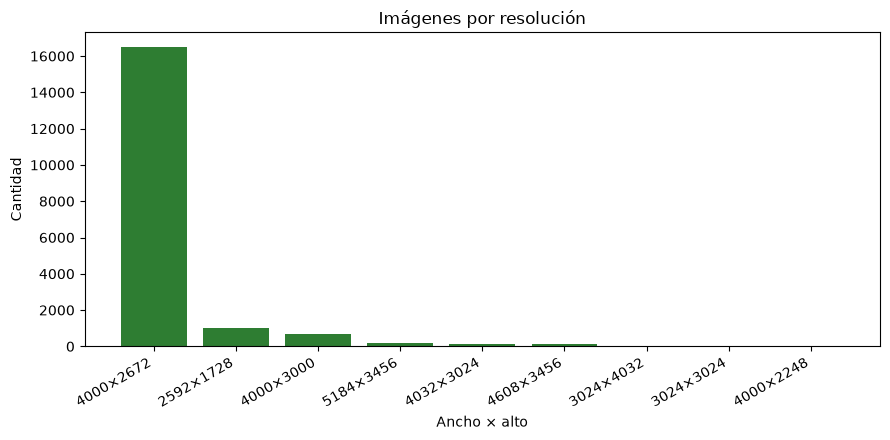

In [5]:
# Construimos una visualización para inspeccionar datos
plt.figure(figsize=(9, 4.5))
plt.bar(resolucion["Resolución"], resolucion["Cantidad"], color="#2e7d32")
plt.title("Imágenes por resolución")
plt.xlabel("Ancho × alto")
plt.ylabel("Cantidad")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 1.2 Etiquetas

`labels` trae una o varias enfermedades separadas por espacio, no se convierten las combinaciones en clases nuevas, cada enfermedad es una salida sí/no

In [6]:
# mostramos la cantidad de etiquetas que tenemos, es decir las clases
clases = ["healthy", "scab", "frog_eye_leaf_spot", "rust", "powdery_mildew", "complex"]
conteo = Counter()
combinaciones = Counter()

# procesamos todos los elementos para comprobar
for texto in auditoria["labels"].astype(str):
    partes = texto.split()
    combinaciones[" ".join(partes)] += 1
    for parte in partes:
        conteo[parte] += 1

por_etiqueta = pd.DataFrame({"Etiqueta": clases, "Imágenes": [conteo[c] for c in clases]})
por_etiqueta["Porcentaje sobre 18632"] = (por_etiqueta["Imágenes"] / len(auditoria) * 100).round(2)
por_etiqueta

,Etiqueta,Imágenes,Porcentaje sobre 18632
0,healthy,4624,24.82
1,scab,5712,30.66
2,frog_eye_leaf_spot,4352,23.36
3,rust,2077,11.15
4,powdery_mildew,1271,6.82
5,complex,2151,11.54


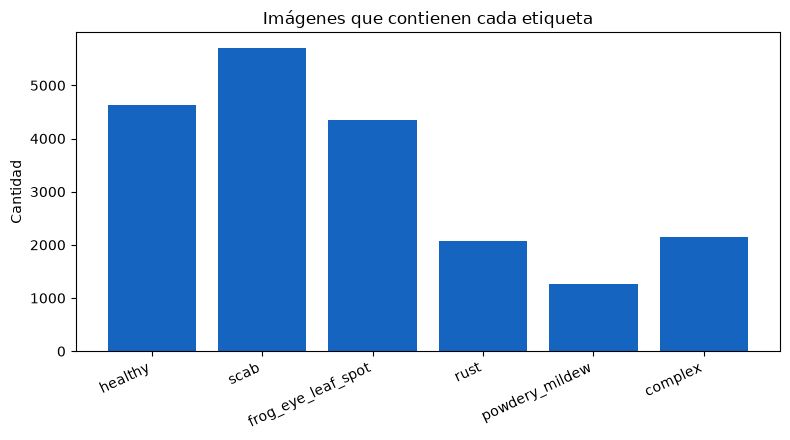

,Combinación,Cantidad
0,scab,4826
1,healthy,4624
2,frog_eye_leaf_spot,3181
3,rust,1860
4,complex,1602
5,powdery_mildew,1184
6,scab frog_eye_leaf_spot,686
7,scab frog_eye_leaf_spot complex,200
8,frog_eye_leaf_spot complex,165
9,rust frog_eye_leaf_spot,120


In [7]:
# creamos una metrica para mostrar la cantidad de imagenes por etiqueta
plt.figure(figsize=(8, 4.5))
plt.bar(por_etiqueta["Etiqueta"], por_etiqueta["Imágenes"], color="#1565c0")
plt.title("Imágenes que contienen cada etiqueta")
plt.ylabel("Cantidad")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

combos = pd.DataFrame(combinaciones.most_common(), columns=["Combinación", "Cantidad"])
combos

### 1.3 Duplicados exactos

El hash MD5 compara el archivo byte a byte. Si dos archivos tienen el mismo MD5, son la misma foto.

Cuando las copias tienen etiquetas distintas se apartan: la misma imagen no puede enseñar dos respuestas a la vez 

In [8]:
# mostramos la tabla de las imagenes duplicadas 
grupos = []
for huella, grupo in duplicados.groupby("md5"):
    etiquetas = sorted(grupo["labels"].unique())
    grupos.append({
        "Archivos": ", ".join(grupo["image"]),
        "Etiquetas": " | ".join(etiquetas),
        "Coinciden": len(etiquetas) == 1,
    })
# llamamos al conteo de los elementos encontrados
tabla_duplicados = pd.DataFrame(grupos)
print("Pares exactos:", len(tabla_duplicados))
print("Pares con etiquetas distintas:", int((~tabla_duplicados["Coinciden"]).sum()))
tabla_duplicados

Pares exactos: 27
Pares con etiquetas distintas: 27


,Archivos,Etiquetas,Coinciden
0,"d2d9c2bca7a72458.jpg, d1dec0973c2cf4a1.jpg",rust | rust frog_eye_leaf_spot,False
1,"ba99260ef46b18cb.jpg, b7b0edd58a858217.jpg",complex | rust,False
2,"f90738a0d2f2c1db.jpg, bd8088cdad5f65e0.jpg",complex | rust,False
3,"f7d233d11aa8496c.jpg, 94b42695f24dad36.jpg",complex | rust,False
4,"e5f27342ce1cb9a0.jpg, ca782c131f5ce0fc.jpg",complex | rust,False
5,"848d9f9e82d18e5e.jpg, 949b6595a5b8ca3c.jpg",complex | rust,False
6,"e9e8ad35c5871d06.jpg, 9ada65c5b0cc9a3c.jpg",complex | rust,False
7,"bb1891fa8c61e663.jpg, aa0e969518e15d3f.jpg",complex | rust,False
8,"ec83c7c04a1e9db9.jpg, 85897ea7f064b26a.jpg",complex | rust,False
9,"8f5263c61a8cdbe2.jpg, c9d63696629107ed.jpg",complex | rust,False


### 1.4 Fotos casi iguales

El hash visual resume cada foto en 64 bits. Dos fotos con 2 bits de diferencia o menos se consideran casi iguales (la misma hoja recortada, recomprimida o con otro brillo). No se borran, pero se obligan a caer en el mismo conjunto

Pares casi iguales : 7


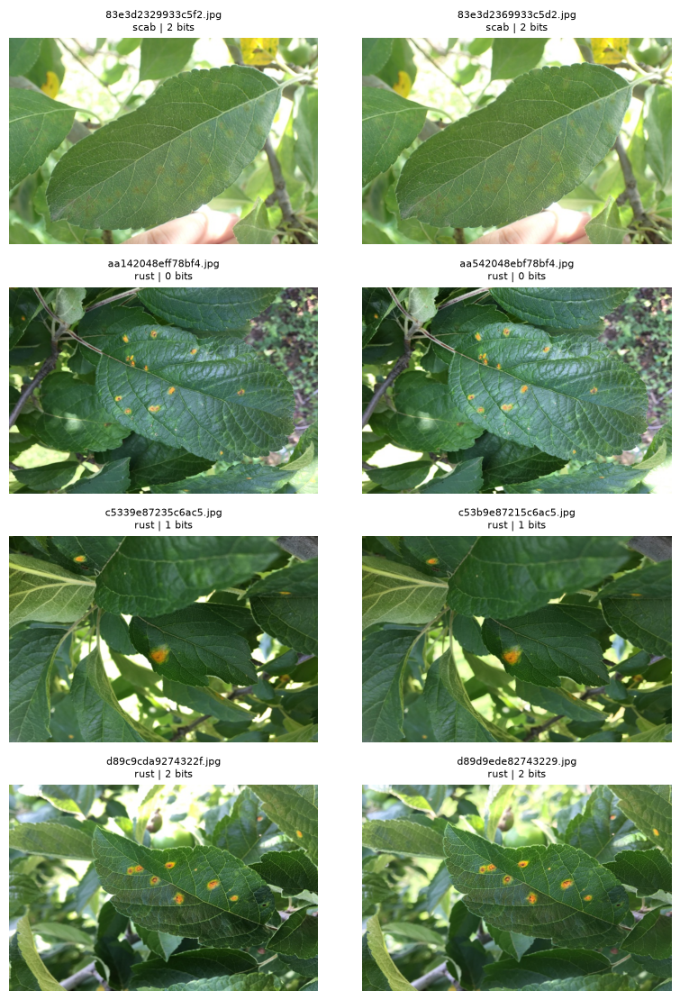

,imagen_a,imagen_b,bits,labels_a,labels_b,exacto
1,83e3d2329933c5f2.jpg,83e3d2369933c5d2.jpg,2,scab,scab,False
17,aa142048eff78bf4.jpg,aa542048ebf78bf4.jpg,0,rust,rust,False
22,c5339e87235c6ac5.jpg,c53b9e87215c6ac5.jpg,1,rust,rust,False
29,d89c9cda9274322f.jpg,d89d9ede82743229.jpg,2,rust,rust,False
30,dfc86b180e3ac8f8.jpg,dfcc6b28063a88fc.jpg,2,rust,rust,False
32,e8210ddefc024fec.jpg,e8212ddeec024fec.jpg,1,rust,rust,False
33,ebd19f1c549a1ad0.jpg,ebd19f9c549a12d0.jpg,0,rust,rust,False


In [9]:
# damos una muestra de las imagenes que han sido manipuladas para aparentar no ser la misma

visuales = pd.read_csv(cfg.RESULTADOS / "duplicados_visuales.csv")
casi = visuales[~visuales["exacto"]]
print("Pares casi iguales :", len(casi))

# condicional identado la que ejecute cuando el len(casi) se ejecute si es verdadero
if len(casi):
    muestra = casi.head(4)
    fig, ejes = plt.subplots(len(muestra), 2, figsize=(8, 2.8 * len(muestra)), squeeze=False)
    for i, fila in enumerate(muestra.itertuples()):
        for j, (nombre, etiqueta) in enumerate([(fila.imagen_a, fila.labels_a), (fila.imagen_b, fila.labels_b)]):
            ejes[i, j].imshow(Image.open(cfg.CACHE / nombre))
            ejes[i, j].set_title(f"{nombre}\n{etiqueta} | {fila.bits} bits", fontsize=8)
            ejes[i, j].axis("off")
    plt.tight_layout()
    plt.show()
casi.head(10)

## 2. Análisis exploratorio

El brillo es el promedio de los píxeles en gris, el contraste es su desviación estándar: si casi todos los píxeles se parecen, el contraste es bajo, la nitidez es la varianza del filtro Laplaciano; un valor más alto indica más bordes en la foto reducida

Estas tres medidas, y los promedios rojo, verde y azul, se calculan sobre una copia de 256 px. esto sirve para comparar fotos entre sí

In [10]:
# leemos un csv en un dataframe de pandas
calidad = pd.read_csv(cfg.RESULTADOS / "calidad_imagenes.csv")
carpeta = cfg.CACHE          
clases = cfg.CLASES

#mostramos en tabla los elementos de los colores de imagenes, es decir ver el RGB
print("Fotos medidas:", len(calidad))
print("Con una sola etiqueta:", int(calidad["una_etiqueta"].sum()))
print("Con varias etiquetas:", int((~calidad["una_etiqueta"]).sum()))
calidad[["brillo", "contraste", "nitidez", "rojo", "verde", "azul"]].describe().round(2)

Fotos medidas: 18578
Con una sola etiqueta: 17230
Con varias etiquetas: 1348


,brillo,contraste,nitidez,rojo,verde,azul
count,18578.00,18578.00,18578.00,18578.00,18578.00,18578.00
mean,142.87,38.90,438.39,124.30,159.85,104.13
std,14.21,9.94,227.72,16.69,15.11,18.07
min,67.12,14.63,37.94,57.68,74.13,33.70
25%,135.54,31.50,296.51,113.94,152.16,92.45
50%,145.07,37.12,396.22,126.00,162.49,104.89
75%,152.35,44.82,527.46,136.09,170.08,116.73
max,193.92,80.47,5154.93,185.54,210.66,169.76


### 2.1 Brillo, contraste y nitidez

La mayoría de las fotos tiene un brillo cercano a 131 y un contraste cercano a 39. Hay colas: fotos más oscuras y fotos más planas. No forman un bloque inutilizable, pero la iluminación no es uniforme
La nitidez varía mucho. El percentil 1 queda cerca de 113 y el máximo pasa de 4500

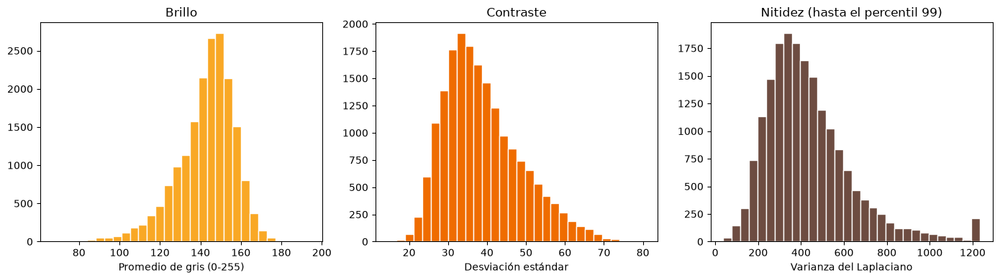

Brillo menor que 90: 62
Brillo mayor que 160: 1429
Contraste menor que 25: 709
Contraste mayor que 65: 269


In [11]:
# construirmos la grafica para revisar las métricas
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
ejes[0].hist(calidad["brillo"], bins=30, color="#f9a825", edgecolor="white")
ejes[0].set_title("Brillo")
ejes[0].set_xlabel("Promedio de gris (0-255)")
ejes[1].hist(calidad["contraste"], bins=30, color="#ef6c00", edgecolor="white")
ejes[1].set_title("Contraste")
ejes[1].set_xlabel("Desviación estándar")
ejes[2].hist(calidad["nitidez"].clip(upper=calidad["nitidez"].quantile(0.99)), bins=30, color="#6d4c41", edgecolor="white")
ejes[2].set_title("Nitidez (hasta el percentil 99)")
ejes[2].set_xlabel("Varianza del Laplaciano")
plt.tight_layout()
plt.show()

#presentamos los datos obetenidos en el conteo de la cantidad obtenida
print("Brillo menor que 90:", int((calidad["brillo"] < 90).sum()))
print("Brillo mayor que 160:", int((calidad["brillo"] > 160).sum()))
print("Contraste menor que 25:", int((calidad["contraste"] < 25).sum()))
print("Contraste mayor que 65:", int((calidad["contraste"] > 65).sum()))

### 2.2 Diferencias entre enfermedades

La comparación usa solo fotos de una etiqueta, la rust es más oscura que el resto, su brillo mediano queda cerca de 113, frente a 39 en las otras, también tiene menos verde

El powdery_mildew tiene la nitidez mediana más baja, puede deberse al aspecto polvoriento de la hoja o a fotos más suaves

In [12]:
# mostramos la lista de los niveles de imagen, como brillo y demás
una = calidad[calidad["una_etiqueta"]]
resumen = []
# buscamos en todos los elementos del dataset
for clase in clases:
    grupo = una[una["labels"] == clase]
    resumen.append({
        "Etiqueta": clase,
        "Fotos": len(grupo),
        "Brillo": round(grupo["brillo"].median(), 1),
        "Contraste": round(grupo["contraste"].median(), 1),
        "Nitidez": round(grupo["nitidez"].median(), 1),
        "Rojo": round(grupo["rojo"].median(), 1),
        "Verde": round(grupo["verde"].median(), 1),
        "Azul": round(grupo["azul"].median(), 1),
    })
tabla = pd.DataFrame(resumen)
tabla

,Etiqueta,Fotos,Brillo,Contraste,Nitidez,Rojo,Verde,Azul
0,healthy,4624,143.8,39.9,447.0,124.1,162.4,101.6
1,scab,4826,142.6,34.8,382.6,121.1,161.3,101.9
2,frog_eye_leaf_spot,3181,148.1,37.1,404.6,128.5,167.1,104.2
3,rust,1833,125.6,40.7,431.3,109.7,140.8,91.0
4,powdery_mildew,1184,144.9,37.6,288.1,131.9,158.6,113.3
5,complex,1582,150.2,34.2,359.3,137.7,164.2,115.2


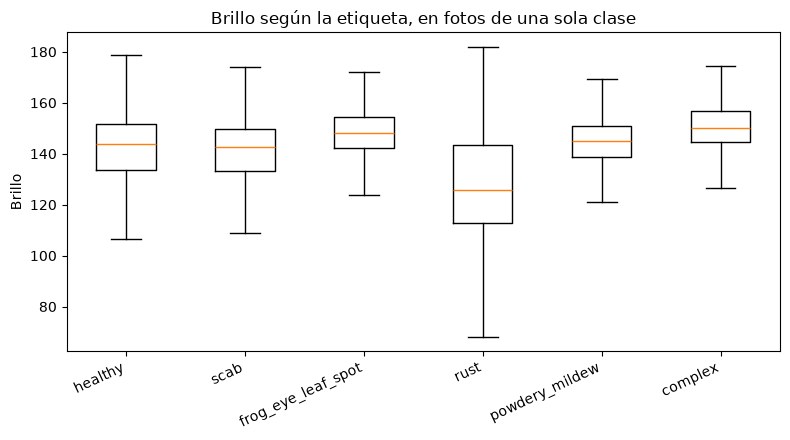

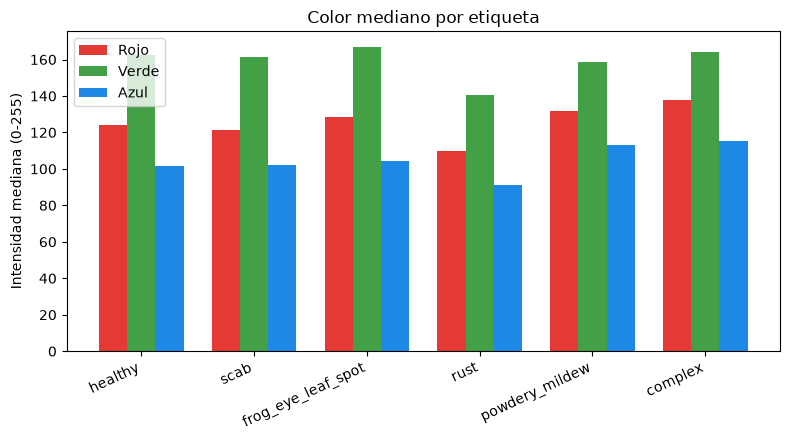

In [14]:
#construimos graficas para que visivilizar los niveles de brillo con un boxspot
#y una grafica para ver la cantidad de colores según el rgb
plt.figure(figsize=(8, 4.5))
plt.boxplot(
    [una.loc[una["labels"] == clase, "brillo"] for clase in clases],
    tick_labels=clases,
    showfliers=False,
)
plt.title("Brillo según la etiqueta, en fotos de una sola clase")
plt.ylabel("Brillo")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
canales = ["Rojo", "Verde", "Azul"]
colores = ["#e53935", "#43a047", "#1e88e5"]
import numpy as np
posiciones = np.arange(len(clases))
ancho = 0.25
for i, canal in enumerate(canales):
    plt.bar(posiciones + i * ancho, tabla[canal], width=ancho, label=canal, color=colores[i])
plt.xticks(posiciones + ancho, clases, rotation=25, ha="right")
plt.ylabel("Intensidad mediana (0-255)")
plt.title("Color mediano por etiqueta")
plt.legend()
plt.tight_layout()
plt.show()

### 2.3 Ejemplos visuales

Cada miniatura es una foto real de una sola etiqueta, elegida por tener un brillo cercano a la mediana de su clase

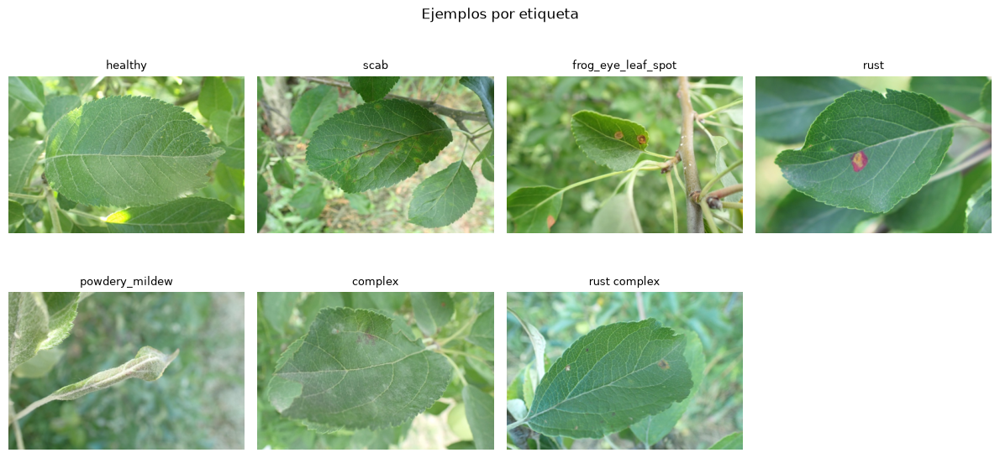

In [16]:
# mostramos una lista de imagenes para visualizar por cada etiqueta o tipo de enfermedad
ejemplos = []
for clase in clases:
    grupo = una[una["labels"] == clase]
    mediana = grupo["brillo"].median()
    fila = grupo.iloc[(grupo["brillo"] - mediana).abs().argmin()]
    ejemplos.append((clase, fila["image"]))

varias = calidad[~calidad["una_etiqueta"]]
mediana = varias["brillo"].median()
fila = varias.iloc[(varias["brillo"] - mediana).abs().argmin()]
ejemplos.append((fila["labels"], fila["image"]))

#asignamos la medida de visualizacion de la imagen
plt.figure(figsize=(12, 6))
#recorremos cada elemento con su nombre y titulo para cada elemento
for i, (titulo, nombre) in enumerate(ejemplos):
    imagen = Image.open(carpeta / nombre).convert("RGB")
    imagen.thumbnail((400, 400))
    plt.subplot(2, 4, i + 1)
    plt.imshow(imagen)
    plt.title(titulo, fontsize=9)
    plt.axis("off")
plt.suptitle("Ejemplos por etiqueta")
plt.tight_layout()
plt.show()

### 2.4 Separación de canales: cómo puede ver el color una computadora

Una foto en color son tres matrices: rojo (R), verde (G) y azul (B)

Esta separación se usa en la sección 7 de la presentación para dibujar el contorno exacto de las manchas.

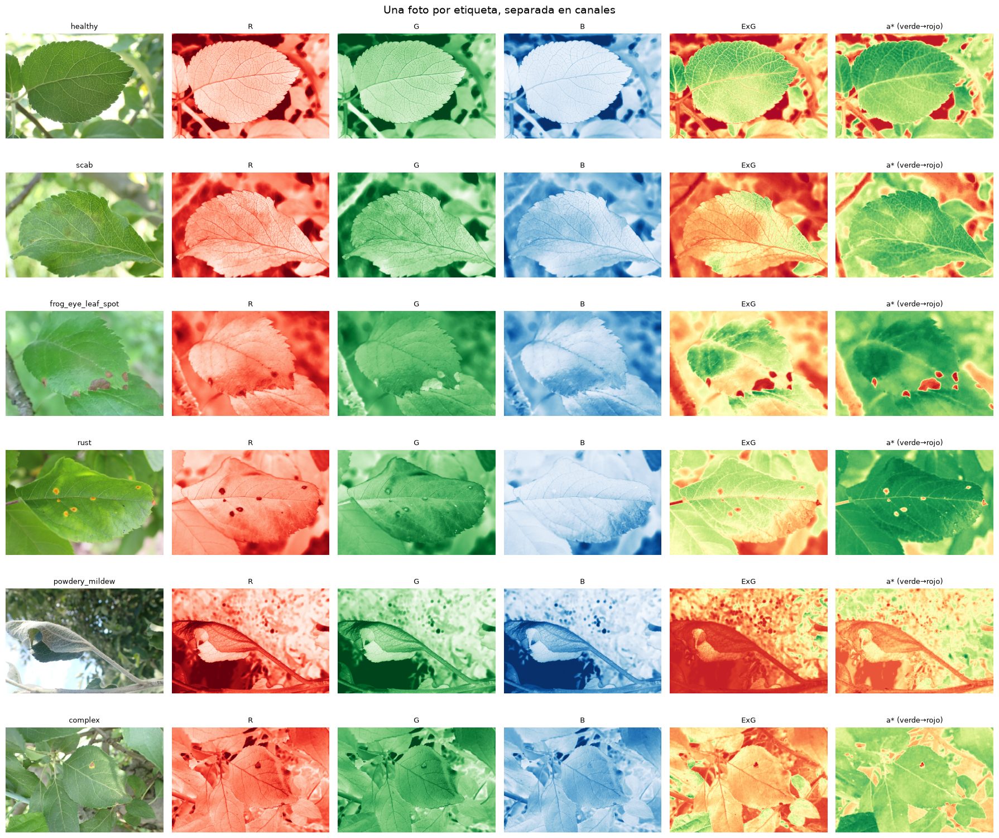

In [21]:
# Importa OpenCV para procesar imágenes y convertir espacios de color
import cv2

# Crea una tabla de gráficos lo que es.. una fila por clase y seis columnas
fig, ejes = plt.subplots(len(clases), 6, figsize=(18, 2.6 * len(clases)))
# Recorre cada clase de enfermedad o estado de la hoja
for i, clase in enumerate(clases):
    # Selecciona aleatoriamente una imagen de la clase, usando una semilla fija
    nombre = una[una["labels"] == clase].sample(1, random_state=7)["image"].iloc[0]

# Abre la imagen y la convierte al formato RGB
    rgb = np.asarray(Image.open(carpeta / nombre).convert("RGB"))
 # Convierte los valores de los píxeles a números decimales
    f = rgb.astype(np.float32)
# Calcula el índice ExG, que resalta la presencia de tonos verdes
    exg = (2 * f[..., 1] - f[..., 0] - f[..., 2]) / (f.sum(-1) + 1e-6)
    
 # Convierte la imagen al espacio de color LAB y extrae el canal a*.
# este canal representa el eje de colores entre verde y rojo
    a = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 1].astype(np.float32) - 128

# Preparamos los seis paneles: imagen original, canales RGB, ExG y canal a*
    paneles = [(rgb, None, f"{clase}"), (rgb[..., 0], "Reds", "R"), (rgb[..., 1], "Greens", "G"),
               (rgb[..., 2], "Blues", "B"), (exg, "RdYlGn", "ExG"), (a, "RdYlGn_r", "a* (verde→rojo)")]

#se recorre los paneles y muestra cada representación de la imagen
    for j, (dato, cmap, titulo) in enumerate(paneles):
        ejes[i, j].imshow(dato, cmap=cmap)     # nos muestra la imagen o el canal de color.
        ejes[i, j].set_title(titulo, fontsize=9) 
        ejes[i, j].axis("off")       # Ocultamos los ejes para mejorar la visualización.

plt.suptitle("Una foto por etiqueta, separada en canales", fontsize=14)
# Ajusta los espacios para evitar que los gráficos se superpongan.
plt.tight_layout()
plt.show()

### 2.5 Qué se observa y qué nos falta por comprobar

Observado en estos archivos:

- `scab` y `healthy` son las etiquetas más frecuentes. `powdery_mildew` es la más escasa: 1 184 fotos de una sola etiqueta, frente a 4 826 de `scab`.
- El verde es el canal más alto en todas las clases. Encaja con hojas, y no separa por sí solo una enfermedad de otra.
- La roya es sistemáticamente más oscura en esta colección. El oídio tiene menos nitidez mediana.
- Hay 1 348 fotos con más de una etiqueta. El modelo tiene que permitir esas combinaciones.
- El dataset solo contiene hojas de manzano, con encuadres e iluminación de este concurso, esto no demuestra cómo se vería otra planta, otro teléfono o una foto a contraluz distinta.

No se eliminó ninguna foto por brillo o por nitidez

## 3. Preparación de los datos

Cada foto se representa con seis columnas sí/no, una por enfermedad. Una combinación como `scab frog_eye_leaf_spot` activa esas dos columnas y deja las otras en cero, es decir no se crea una clase nueva por cada combinación


In [22]:
# Importamos la función que lee las divisiones de datos guardadas por el proyecto.
from codigo.datos import leer_division

# se define los cuatro conjuntos de imágenes que se van a revisar
conjuntos = ["entrenamiento", "validacion", "prueba", "apartadas"]
# Carga los datos de cada conjunto y los almacena en un diccionario
partes = {nombre: leer_division(nombre) for nombre in conjuntos}

# se crea una tabla con el nombre de cada conjunto y su cantidad de fotos
resumen = pd.DataFrame({"Conjunto": conjuntos, "Fotos": [len(partes[n]) for n in conjuntos]})
print("Total:", int(resumen["Fotos"].sum()))

# Buscamos imágenes repetidas entre entrenamiento y los conjuntos de validación o prueba
comunes = set(partes["entrenamiento"]["image"]) & (set(partes["validacion"]["image"]) | set(partes["prueba"]["image"]))
# Muestra cuántas imágenes están repetidas entre esos conjuntos
print("Fotos repetidas entre entrenamiento y validación/prueba:", len(comunes))

# Mostramos la tabla resumen con la cantidad de fotos por conjunto
resumen

Total: 18632
Fotos repetidas entre entrenamiento y validación/prueba: 0


,Conjunto,Fotos
0,entrenamiento,13006
1,validacion,2786
2,prueba,2786
3,apartadas,54


In [23]:
# Lista vacia donde se guardarán los resultados de cada etiqueta
filas = []

# Recorre cada enfermedad o estado de la hoja
for clase in clases:
# Creamos una fila con el nombre de la etiqueta
    fila = {"Etiqueta": clase}

# se revisa los conjuntos de entrenamiento, validación y prueba
    for nombre in ["entrenamiento", "validacion", "prueba"]:
 # Obtenemos la tabla correspondiente al conjunto actual
        tabla = partes[nombre]

# Calcula el porcentaje de imágenes que contienen esta etiqueta
# mean() obtiene la proporción de valores positivos
        fila[nombre] = round(100 * tabla[clase].mean(), 2)
# Guarda los porcentajes calculados para esta etiqueta
    filas.append(fila)
# Convierte los resultados en una tabla para comparar los porcentajes por conjunto
pd.DataFrame(filas)

,Etiqueta,entrenamiento,validacion,prueba
0,healthy,24.89,24.91,24.87
1,scab,30.74,30.76,30.76
2,frog_eye_leaf_spot,23.41,23.44,23.44
3,rust,11.01,10.98,10.95
4,powdery_mildew,6.84,6.82,6.86
5,complex,11.43,11.45,11.45


### 3.1 Tamaño, aumentación y normalización

**Orientación y tamaño.** Todas las fotos se ponen en horizontal y se llevan a 672×448 en la caché, desde ahí la red recibe **576×384** (perfil preciso) o **480×320** (perfil rápido)
Se conserva la proporción 3:2 del dataset en vez de aplastar la hoja a un cuadrado de 224×224 asi las manchas pequeñas siguen siendo visibles

**Normalización.** `ToTensor` pasa los píxeles de 0–255 a 0–1; después se resta la media y se divide por la desviación de ImageNet porque la red se preentrenó así

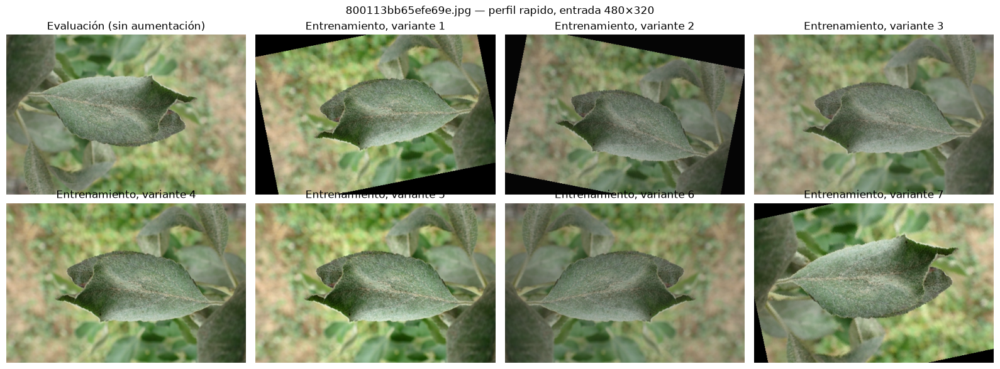

Tensor de entrada: (3, 320, 480) | mínimo -1.638 | máximo 1.868


In [24]:
# Importa las transformaciones para preparar imágenes de entrenamiento y evaluación
from codigo.datos import transformacion_entrenamiento, transformacion_evaluacion

# Selecciona el perfil de configuración y obtiene el tamaño de entrada del modelo
nombre_perfil, perfil = cfg.elegir_perfil()
tam = perfil["tam_entrada"]
# Selecciona la primera imagen del conjunto de entrenamiento y la abre en RGB
ejemplo = partes["entrenamiento"]["image"].iloc[0]
imagen = Image.open(cfg.CACHE / ejemplo).convert("RGB")
# Crea las transformaciones
t_ent, t_eval = transformacion_entrenamiento(tam), transformacion_evaluacion(tam)

# Convierte un tensor normalizado nuevamente a una imagen visible
def a_imagen(t):
# Recupera la media y desviación estándar utilizadas para normalizar las imágenes
    m, s = torch.tensor(cfg.MEDIA_IMAGENET)[:, None, None], torch.tensor(cfg.DESV_IMAGENET)[:, None, None]
    # Desnormaliza los valores, limita el rango a [0, 1] y cambia el orden de los canales
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# Crea una cuadrícula de dos filas y cuatro columnas para comparar las transformaciones
fig, ejes = plt.subplots(2, 4, figsize=(16, 6))
# Muestra la imagen transformada para evaluación, sin aumentación aleatoria
ejes[0, 0].imshow(a_imagen(t_eval(imagen)))
ejes[0, 0].set_title("Evaluación (sin aumentación)")

# Muestra varias versiones de la misma imagen con transformaciones de entrenamiento
for k, ax in enumerate(ejes.flat[1:]):
    ax.imshow(a_imagen(t_ent(imagen)))
    ax.set_title(f"Entrenamiento, variante {k + 1}")
# Oculta los ejes para que las imágenes se vean con mayor claridad
for ax in ejes.flat:
    ax.axis("off")

# Añade el nombre de la imagen, el perfil y el tamaño de entrada al gráfico
plt.suptitle(f"{ejemplo} — perfil {nombre_perfil}, entrada {tam[0]}×{tam[1]}")
plt.tight_layout()  
plt.show()  

# Transforma la imagen para evaluación y obtiene su tensor de entrada
tensor = t_eval(imagen)
# Muestra la forma del tensor y sus valores mínimo y máximo para verificar la preparación
print("Tensor de entrada:", tuple(tensor.shape), "| mínimo", round(float(tensor.min()), 3), "| máximo", round(float(tensor.max()), 3))

## 4. Fundamentos matemáticos

Esta sección explica las piezas de una red, con números pequeños que se pueden recalcular a mano, no clasifica las hojas
El modelo de las enfermedades usa muchas de estas operaciones en los pasos que veremos más adelante en las capas convolucionales

Hay dos umbrales distintos y no se deben mezclar:

- El umbral de una neurona clásica decide si esa neurona devuelve 0 o 1
- El umbral de decisión, al final del clasificador convierte una probabilidad en una etiqueta

### 4.1 Neurona de McCulloch-Pitts

La neurona de McCulloch-Pitts recibe entradas binarias, las suma y las compara con un umbral 

$$
z = x_1 + x_2 + x_3
$$

$$
f(z) =
\begin{cases}
1 & \text{si } z \ge \theta \\
0 & \text{si } z < \theta
\end{cases}
$$

En el ejemplo, tres entradas valen 0 o 1 y el umbral es 2
La neurona se activa solo si al menos dos entradas están en 1. No hay pesos: todas las entradas cuentan igual

In [25]:
# Importamos itertools para generar todas las combinaciones posibles de entradas
import itertools
# Importamos Pandas para organizar los resultados en una tabla
import pandas as pd

# Define el umbral: la neurona se activa cuando la suma es mayor o igual a 2.
umbral = 2
# Creamos una lista vacía para almacenar los resultados
filas = []
# se genera las 8 combinaciones posibles de tres entradas binarias 
for entradas in itertools.product([0, 1], repeat=3):
 # Suma las entradas para calcular z
    suma = sum(entradas)

# Guarda las entradas, la suma y la salida de la neurona
    filas.append({
        "x1": entradas[0], 
        "x2": entradas[1],  
        "x3": entradas[2],  
        "z": suma,    # Suma de las entradas: z = x1 + x2 + x3
        "f(z)": int(suma >= umbral),  # Devuelve 1 si alcanza el umbral sino de lo contrario es 0
    })
# Convierte los resultados en una tabla para visualizar el funcionamiento de la neurona
pd.DataFrame(filas)

,x1,x2,x3,z,f(z)
0,0,0,0,0,0
1,0,0,1,1,0
2,0,1,0,1,0
3,0,1,1,2,1
4,1,0,0,1,0
5,1,0,1,2,1
6,1,1,0,2,1
7,1,1,1,3,1


### 4.2 Suma simple y suma ponderada

La suma simple trata igual a todas las entradas:

$$
z = x_1 + x_2 + x_3
$$

La suma ponderada multiplica cada entrada por un peso
Un peso grande hace que esa entrada influya más

$$
z = w_1 x_1 + w_2 x_2 + w_3 x_3
$$

Con las mismas entradas \((1, 0, 1)\), la suma simple vale 2. Si los pesos son \(0.2\), \(3\) y \(0.5\), la suma ponderada vale \(0.7\) 
La tercera entrada sigue presente, pero pesa poco

In [26]:
# Define las tres entradas de la neurona
entradas = (1, 0, 1)
# Define el peso que se asigna a cada entrada para calcular su importancia
pesos = (0.2, 3.0, 0.5)

# Suma las entradas sin considerar sus pesos
suma_simple = sum(entradas)

# Calcula la suma ponderada multiplicando cada entrada por su peso correspondiente
# zip() empareja cada peso con su entrada y sum() suma los productos obtenidos
suma_ponderada = sum(peso * entrada for peso, entrada in zip(pesos, entradas))

print("Suma simple:", suma_simple)
print("Suma ponderada:", suma_ponderada)

Suma simple: 2
Suma ponderada: 0.7


### 4.3 Perceptrón

El perceptrón añade el sesgo \(b\)
El sesgo permite activar la neurona aunque todas las entradas sean cero o exigir una suma más alta antes de activarla

$$
z = w_1 x_1 + w_2 x_2 + b
$$

$$
f(z) =
\begin{cases}
1 & \text{si } z \ge 0 \\
0 & \text{si } z < 0
\end{cases}
$$

El peso dice cuánto empuja cada entrada 
El sesgo desplaza ese resultado
El umbral de esta neurona está en cero porque el sesgo ya absorbió el desplazamiento

Abajo, un perceptrón aprende la función AND. La regla, con tasa \(\eta = 0.1\), es:

$$
w \leftarrow w + \eta (y - \hat{y}) x, \qquad b \leftarrow b + \eta (y - \hat{y})
$$

\(y\) es la respuesta correcta y \(\hat{y}\) es la predicción. Si acierta, no cambia nada

In [27]:
import numpy as np
# Define las cuatro combinaciones posibles de dos entradas binarias
entradas = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)

# Define las respuestas esperadas para la compuerta lógica AND
# La salida es 1 únicamente cuando las dos entradas son 1
respuestas = np.array([0, 0, 0, 1], dtype=float)
# Inicializa los pesos de las dos entradas en cero
pesos = np.zeros(2)
# Inicializa el sesgo de la neurona en cero.
sesgo = 0.0
# Define la tasa de aprendizaje para actualizar los pesos y el sesgo
tasa = 0.1

# Define una función que calcula la predicción de la neurona para una fila de entradas
def predecir(fila):
# Multiplica los pesos por las entradas, suma el sesgo y devuelve 1 si el resultado es mayor o igual a cero; de lo contrario, devuelve 0
    return int(np.dot(pesos, fila) + sesgo >= 0)

# Entrena la neurona durante 7 épocas, recorriendo los datos en cada una
for epoca in range(1, 8):
    for fila, respuesta in zip(entradas, respuestas):
        prediccion = predecir(fila)
        error = respuesta - prediccion
        pesos = pesos + tasa * error * fila
        sesgo = sesgo + tasa * error

 # Calcula las predicciones de la neurona para las cuatro combinaciones de entradas después de cada época
    predicciones = [predecir(fila) for fila in entradas]
    print(f"Época {epoca}: pesos {pesos.round(1)}, sesgo {sesgo:.1f}, predicciones {predicciones}")

Época 1: pesos [0.1 0.1], sesgo 0.0, predicciones [1, 1, 1, 1]
Época 2: pesos [0.2 0.1], sesgo -0.1, predicciones [0, 1, 1, 1]
Época 3: pesos [0.2 0.1], sesgo -0.2, predicciones [0, 0, 0, 1]
Época 4: pesos [0.2 0.1], sesgo -0.2, predicciones [0, 0, 0, 1]
Época 5: pesos [0.2 0.1], sesgo -0.2, predicciones [0, 0, 0, 1]
Época 6: pesos [0.2 0.1], sesgo -0.2, predicciones [0, 0, 0, 1]
Época 7: pesos [0.2 0.1], sesgo -0.2, predicciones [0, 0, 0, 1]


### 4.4 Funciones de activación

La función de activación transforma \(z\) en la salida de la neurona

- **Escalón:** devuelve solo 0 o 1. Es la función del perceptrón. No tiene una pendiente útil para ajustar miles de pesos, por eso no se usa dentro de EfficientNet
- **ReLU:** devuelve 0 si \(z\) es negativo y deja pasar \(z\) si es positivo. Es la habitual en las capas internas de las redes convolucionales
- **Sigmoide:** comprime cualquier número al intervalo \((0, 1)\). En este proyecto irá al final, una por enfermedad, porque cada etiqueta puede estar presente o no. No se usa softmax: softmax obligaría a elegir una sola clase

$$
\mathrm{ReLU}(z) = \max(0, z), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}
$$

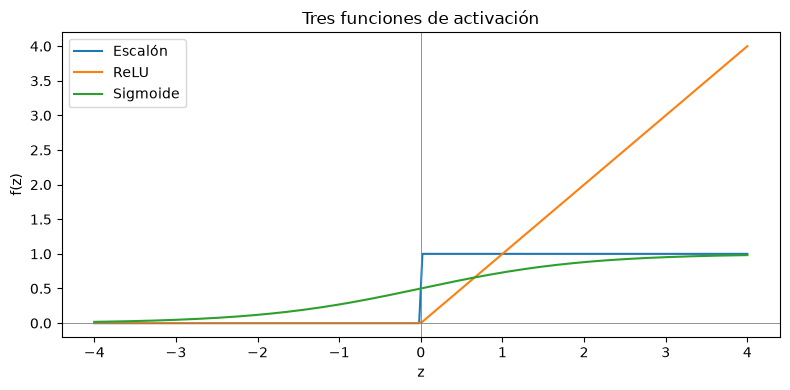

,z,Escalón,ReLU,Sigmoide
0,-2.0,0,0.0,0.119
1,-1.0,0,0.0,0.269
2,0.0,1,0.0,0.500
3,1.0,1,1.0,0.731
4,2.0,1,2.0,0.881


In [28]:
# Define los valores de z que se utilizarán para comparar las funciones de activación
valores = np.array([-2, -1, 0, 1, 2], dtype=float)
# Calcula la función escalón: devuelve 1 si el valor es mayor o igual a 0; de lo contrario, devuelve 0
escalon = (valores >= 0).astype(int)

# Calcula la función ReLU: devuelve el valor de z si es positivo y 0 si es negativo
relu = np.maximum(0, valores)
# Calcula la función sigmoide, que transforma los valores en números entre 0 y 1
sigmoide = 1 / (1 + np.exp(-valores))

# Crea una tabla con los valores de z y los resultados de las tres funciones de activación
tabla = pd.DataFrame({
    "z": valores,  
    "Escalón": escalon, 
    "ReLU": relu, 
    "Sigmoide": sigmoide.round(3),  
})

# Genera 200 valores equidistantes entre -4 y 4 para dibujar las curvas de las funciones
curva = np.linspace(-4, 4, 200)
# Crea una figura para mostrar las tres funciones de activación en una misma gráfica
plt.figure(figsize=(8, 4))
# Dibuja la función escalón utilizando los valores de la curva
plt.plot(curva, (curva >= 0).astype(float), label="Escalón")
# Dibuja la función ReLU utilizando los valores de la curva
plt.plot(curva, np.maximum(0, curva), label="ReLU")
# Dibuja la función sigmoide utilizando los valores de la curva
plt.plot(curva, 1 / (1 + np.exp(-curva)), label="Sigmoide")
# Añade una línea horizontal en y = 0 para facilitar la lectura de la gráfica
plt.axhline(0, color="gray", linewidth=0.6)
# Añade una línea vertical en z = 0 para identificar el punto donde cambia el comportamiento de las funciones
plt.axvline(0, color="gray", linewidth=0.6)
plt.title("Tres funciones de activación")
plt.xlabel("z")

# Etiqueta el eje vertical con la salida de las funciones de activación
plt.ylabel("f(z)")
# Muestra la leyenda para identificar cada función en la gráfica
plt.legend()
# Ajusta los espacios de la figura para que los elementos se visualicen correctamente
plt.tight_layout()
plt.show()
# Muestra la tabla con los valores de z y los resultados calculados para cada función
tabla

### 4.5 Cómo se ajustan los pesos

Para cada enfermedad, la salida es una probabilidad. Si la etiqueta correcta es 1 ó 0 y el modelo dice la entropía cruzada binaria vale:

$$
L = -\left[y \log \hat{y} + (1 - y) \log (1 - \hat{y})\right]
$$

Cuanto más lejos está \(\hat{y}\) de \(y\), más grande es \(L\). El gradiente indica en qué dirección crece esa pérdida
El optimizador da un paso en la dirección contraria y actualiza los pesos

Una neurona clásica combina variables ya resumidas, por ejemplo el brillo medio
Una convolución no ve la foto entera de una vez: un filtro pequeño recorre la imagen, suma los píxeles vecinos con los mismos pesos y detecta un borde o una mancha local

In [29]:
import math

def perdida(y, probabilidad):
    probabilidad = min(max(probabilidad, 1e-8), 1 - 1e-8)
    return -(y * math.log(probabilidad) + (1 - y) * math.log(1 - probabilidad))

print("Etiqueta presente y probabilidad 0.20. Pérdida:", round(perdida(1, 0.20), 3))
print("Etiqueta presente y probabilidad 0.90. Pérdida:", round(perdida(1, 0.90), 3))

parche = np.array([
    [20, 20, 20],
    [20, 180, 180],
    [20, 180, 180],
], dtype=float)
filtro = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1],
], dtype=float)
respuesta = float((parche * filtro).sum())
print("Suma local del filtro sobre el parche:", respuesta)

Etiqueta presente y probabilidad 0.20. Pérdida: 1.609
Etiqueta presente y probabilidad 0.90. Pérdida: 0.105
Suma local del filtro sobre el parche: 320.0


### 4.6 Umbral de la neurona y umbral de decisión

El escalón de la sección 4.3 responde una pregunta interna: ¿esta neurona se enciende? El clasificador de hojas hará otra pregunta, ya con el entrenamiento terminado: ¿esta probabilidad basta para marcar la enfermedad?

Los números de abajo son un ejemplo inventado para ver la diferencia

Con un umbral fijo de 0.50, una probabilidad de 0.42 no marca la roya. Con un umbral de 0.35, sí la marca
Bajar el umbral encuentra más casos y también puede aumentar los falsos avisos
Cada etiqueta puede necesitar un umbral distinto porque unas enfermedades tienen muchas más fotos que otras

In [30]:
ejemplo = pd.DataFrame({
    "Etiqueta": ["healthy", "scab", "rust"],
    "Probabilidad": [0.10, 0.62, 0.42],
    "Umbral fijo 0.50": [0, 1, 0],
    "Umbral de ejemplo": [0.50, 0.50, 0.35],
})
ejemplo["Decisión con umbral de ejemplo"] = (
    ejemplo["Probabilidad"] >= ejemplo["Umbral de ejemplo"]
).astype(int)
ejemplo

,Etiqueta,Probabilidad,Umbral fijo 0.50,Umbral de ejemplo,Decisión con umbral de ejemplo
0,healthy,0.10,0,0.50,0
1,scab,0.62,1,0.50,1
2,rust,0.42,0,0.35,1


## 5. Entrenamiento

### 5.1 Elección del modelo

| Criterio | MobileNetV3-Large (versión anterior) | EfficientNet-B0 (perfil rápido) | EfficientNetV2-S (perfil preciso) |
|---|---|---|---|
| Parámetros | 5,5 M | 5,3 M | 21,5 M |
| Exactitud ImageNet top-1 | 75,3 % | 77,7 % | 84,2 % |
| Entrada usada | 224×224 (aplastada) | 480×320 | 576×384 |
| Hardware | cualquiera | CPU / MPS / GPU pequeña | GPU NVIDIA ≥ 6 GB |

Se usa **transfer learning**: las capas convolucionales llegan con los pesos aprendidos en ImageNet (bordes, texturas, formas) y solo se cambia la última capa, que distinguía 1 000 objetos, por **6 salidas** independientes. Cada salida pasa por una **sigmoide** (no softmax), porque una hoja puede tener varias enfermedades. 
La pérdida es **entropía cruzada binaria con logits** (`BCEWithLogitsLoss`), que aplica la sigmoide de forma numéricamente estable.

Las dos arquitecturas son de la misma familia, así el resto del código (mapas de atención, inferencia) no cambia.

### 5.2 Cómo se entrena

1. **Cabeza (2 épocas):** cuerpo congelado, solo aprende la capa nueva (tasa 0,001). Evita que los gradientes grandes del principio destruyan lo preentrenado.
2. **Ajuste fino (hasta 12–15 épocas):** se descongela toda la red, AdamW con tasa baja, calentamiento del 5 % de los pasos y descenso coseno. La capa final aprende 5 veces más rápido que el cuerpo.

- **Desbalance:** cada etiqueta pesa en la pérdida según √(negativos/positivos), calculado solo con entrenamiento. La raíz suaviza el efecto (el peso completo inflaba las probabilidades del oídio y obligaba a umbrales de 0,94).
- **Criterio de checkpoint:** la menor **pérdida de validación**, fijado antes de entrenar. El F1 con umbral 0,5 y el mAP se muestran solo como vigilancia.
- **Paro temprano:** 3 épocas sin mejorar la pérdida de validación.
- **Precisión mixta** (float16) en GPU NVIDIA: casi el doble de rápido y menos memoria.
- **Reanudación:** al final de cada época se guarda `modelos/ultimo_estado.pt`. Si el entrenamiento se corta, vuelve a ejecutar la celda y continúa donde quedó.
- Semilla 42 en Python, NumPy y PyTorch.

In [31]:
from codigo import entrenamiento

nombre_perfil, perfil = cfg.elegir_perfil()
print("Perfil elegido:", nombre_perfil)
pd.Series(perfil, name="valor").to_frame()

Perfil elegido: rapido


,valor
arquitectura,efficientnet_b0
tam_entrada,"(480, 320)"
lote,24
epocas_cabeza,2
epocas_ajuste,12
lr_cabeza,0.001
lr_ajuste,0.0003
paciencia,3


**Prueba rápida** Entrenar 15 lotes por fase solo para comprobar que todo funciona (lectura de la caché, GPU, memoria, guardado). No toca el modelo real.

In [33]:
PRUEBA_RAPIDA = False 
if PRUEBA_RAPIDA:
    entrenamiento.entrenar(prueba_rapida=True, reanudar=False)

**Entrenamiento completo** 

In [35]:
REENTRENAR = False
ya_entrenado = (cfg.RESULTADOS / "historial_entrenamiento.csv").exists()

if REENTRENAR or not ya_entrenado:
    historial = entrenamiento.entrenar(reanudar=not REENTRENAR)
else:
    print("Ya hay un entrenamiento terminado. Se usan modelos/modelo.pt y el historial guardado")

Ya hay un entrenamiento terminado. Se usan modelos/modelo.pt y el historial guardado


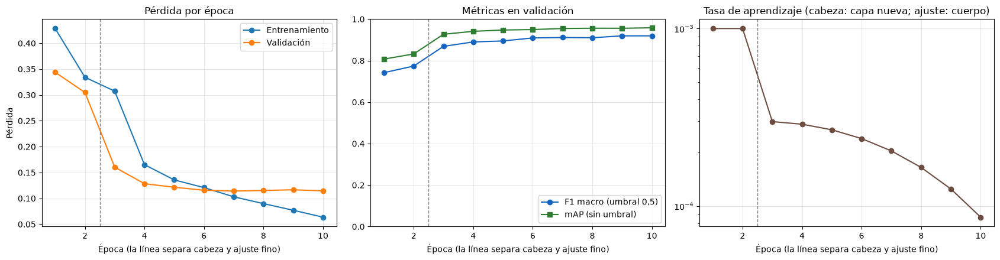

Mejor pérdida de validación: 0.1141 en ajuste época 5
F1 macro (0,5) en esa época: 0.911 | mAP: 0.955
Tiempo total: 1012.9 min


,fase,epoca,perdida_entrenamiento,perdida_validacion,f1_macro_validacion,map_validacion,lr,segundos,paso
0,cabeza,1,0.4284,0.3438,0.7419,0.8074,0.001000,2579.7,1
1,cabeza,2,0.3342,0.3048,0.7738,0.8321,0.001000,2402.6,2
2,ajuste,1,0.3073,0.1603,0.8687,0.9270,0.000299,7780.0,3
3,ajuste,2,0.1652,0.1284,0.8900,0.9411,0.000289,6911.2,4
4,ajuste,3,0.1357,0.1215,0.8948,0.9474,0.000269,6732.1,5
5,ajuste,4,0.1208,0.1157,0.9092,0.9496,0.000240,6491.4,6
6,ajuste,5,0.1030,0.1141,0.9113,0.9548,0.000205,7228.0,7
7,ajuste,6,0.0898,0.1152,0.9102,0.9561,0.000165,6800.4,8
8,ajuste,7,0.0770,0.1166,0.9193,0.9558,0.000125,6973.4,9
9,ajuste,8,0.0636,0.1145,0.9195,0.9582,0.000087,6874.8,10


In [36]:
# Carga el historial de entrenamiento desde un archivo CSV ubicado en la carpeta de resultados
historial = pd.read_csv(cfg.RESULTADOS / "historial_entrenamiento.csv")

# Añade una columna con el número de paso o época, comenzando desde 1
historial["paso"] = range(1, len(historial) + 1)
# Calcula el punto de separación entre las fases de entrenamiento de la cabeza y ajuste fino
# Cuenta las épocas de la fase "cabeza" y suma 0.5 para colocar la línea divisoria entre dos épocas
corte = (historial["fase"] == "cabeza").sum() + 0.5
# Crea una figura con tres gráficos organizados en una fila
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

# Dibuja la pérdida de entrenamiento en función de cada época, utilizando marcadores circulares
ejes[0].plot(historial["paso"], historial["perdida_entrenamiento"], marker="o", label="Entrenamiento")
# Dibuja la pérdida de validación para comparar su evolución con la pérdida de entrenamiento
ejes[0].plot(historial["paso"], historial["perdida_validacion"], marker="o", label="Validación")
ejes[0].set_title("Pérdida por época")
ejes[0].set_ylabel("Pérdida")
# Muestra la leyenda para distinguir las curvas de entrenamiento y validación.
ejes[0].legend()

# Dibuja la evolución del F1 macro de validación, calculado con un umbral de 0.5
ejes[1].plot(historial["paso"], historial["f1_macro_validacion"], marker="o", color="#1565c0", label="F1 macro (umbral 0,5)")
# Dibuja la evolución del mAP de validación, una métrica que evalúa el ordenamiento de las predicciones sin aplicar un umbral fijo
ejes[1].plot(historial["paso"], historial["map_validacion"], marker="s", color="#2e7d32", label="mAP (sin umbral)")
# Establece los límites del eje vertical entre 0 y 1, rango habitual de estas métricas
ejes[1].set_ylim(0, 1)

ejes[1].set_title("Métricas en validación")
# Muestra la leyenda para identificar las curvas del F1 macro y del mAP
ejes[1].legend()
# Dibuja la evolución de la tasa de aprendizaje durante el entrenamiento
ejes[2].plot(historial["paso"], historial["lr"], marker="o", color="#6d4c41")
# Configura la escala logarítmica del eje vertical para visualizar mejor los cambios en la tasa de aprendizaje
ejes[2].set_yscale("log")
# Añade el título al tercer gráfico e indica las dos fases del entrenamiento
ejes[2].set_title("Tasa de aprendizaje (cabeza: capa nueva; ajuste: cuerpo)")

# Recorre los tres gráficos para añadir elementos comunes
for ax in ejes:
    # Dibuja una línea vertical discontinua que separa la fase de entrenamiento de la cabeza del ajuste fino
    ax.axvline(corte, color="gray", linestyle="--", linewidth=1)
    # Etiqueta el eje horizontal con el número de época y explica el significado de la línea divisoria
    ax.set_xlabel("Época (la línea separa cabeza y ajuste fino)")
    # Añade una cuadrícula con transparencia para facilitar la lectura de los valores
    ax.grid(alpha=0.3)

# Ajusta los espacios entre los gráficos para mejorar su distribución
plt.tight_layout()
# Muestra los tres gráficos del historial de entrenamiento
plt.show()

# Busca la fila del historial que tiene la menor pérdida de validación y guarda sus datos
mejor = historial.loc[historial["perdida_validacion"].idxmin()]
print(f"Mejor pérdida de validación: {mejor['perdida_validacion']:.4f} en {mejor['fase']} época {int(mejor['epoca'])}")
print(f"F1 macro (0,5) en esa época: {mejor['f1_macro_validacion']:.3f} | mAP: {mejor['map_validacion']:.3f}")
print(f"Tiempo total: {historial['segundos'].sum() / 60:.1f} min")

# Muestra la tabla completa con los datos del historial de entrenamiento
historial

### 5.3 Cómo leer estas curvas

- Si la pérdida de **entrenamiento** sigue bajando mientras la de **validación** sube, el modelo empieza a memorizar (sobreajuste). Por eso se guarda el checkpoint de menor pérdida de validación y se para a las 3 épocas sin mejora.
- El salto al empezar el ajuste fino es esperado: al descongelar la red, todas las capas se adaptan a las hojas.
- El **mAP** (precisión media) no depende de ningún umbral; el F1 con 0,5 sí, y todavía no está calibrado. Por eso ninguno decide el checkpoint.
- Anota aquí, después de entrenar, en qué época quedó el mejor modelo y si hubo sobreajuste: son conclusiones que deben salir de tus curvas, no de este texto.

## 6. Umbrales y evaluación final

El modelo entrega una probabilidad por enfermedad. 
Marcar la etiqueta cuando esa probabilidad pasa de 0.50 es un punto de partida, no una ley
Como unas clases son mucho más escasas que otras, cada etiqueta puede necesitar su propio corte

El criterio se fijó antes de abrir la prueba: en validación, para cada etiqueta, se elige el umbral entre 0.05 y 0.95 que maximiza el F1. Si dos umbrales empatan, se queda el más cercano a 0.50. Esos seis números se guardan en `modelos/umbrales.json` y ya no se mueven

Precision dice, de las veces que el modelo marca la enfermedad, cuántas son correctas. Recall dice, de las hojas que sí tienen la enfermedad, cuántas encuentra
El F1 resume las dos. Una exactitud alta puede engañar: si casi ninguna foto tiene oídio, decir siempre que no lo tiene acierta la mayoría y no sirve

ROC-AUC y PR-AUC no dependen del umbral. PR-AUC importa más cuando la clase positiva es escasa


Las probabilidades de validación y prueba se calculan con **TTA** (promedio de la foto y su espejo horizontal), igual que en la inferencia de la sección 8.

In [37]:
# Define la ruta del archivo CSV que contiene las métricas obtenidas durante la evaluación de prueba
metricas_csv = cfg.RESULTADOS / "metricas_prueba.csv"

# Comprueba si el archivo de métricas no existe o si fue modificado antes que el archivo del modelo
# Si se cumple alguna de estas condiciones, vuelve a evaluar el modelo y calibrar los umbrales
if not metricas_csv.exists() or metricas_csv.stat().st_mtime < cfg.ARCHIVO_MODELO.stat().st_mtime:
    resumen_prueba = entrenamiento.evaluar_y_calibrar()

# Lee el archivo JSON con el resumen de la evaluación de prueba y guarda sus datos
resumen_prueba = cfg.leer_json(cfg.RESULTADOS / "resumen_prueba.json")
# Obtiene los umbrales seleccionados durante la validación para cada etiqueta o clase
umbrales = resumen_prueba["umbrales"]

# Convierte los umbrales en una serie de Pandas y después en una tabla de una columna
# el nombre de la columna indica que los umbrales fueron elegidos durante la validación
pd.Series(umbrales, name="umbral elegido en validación").to_frame()

,umbral elegido en validación
healthy,0.51
scab,0.77
frog_eye_leaf_spot,0.68
rust,0.50
powdery_mildew,0.59
complex,0.42


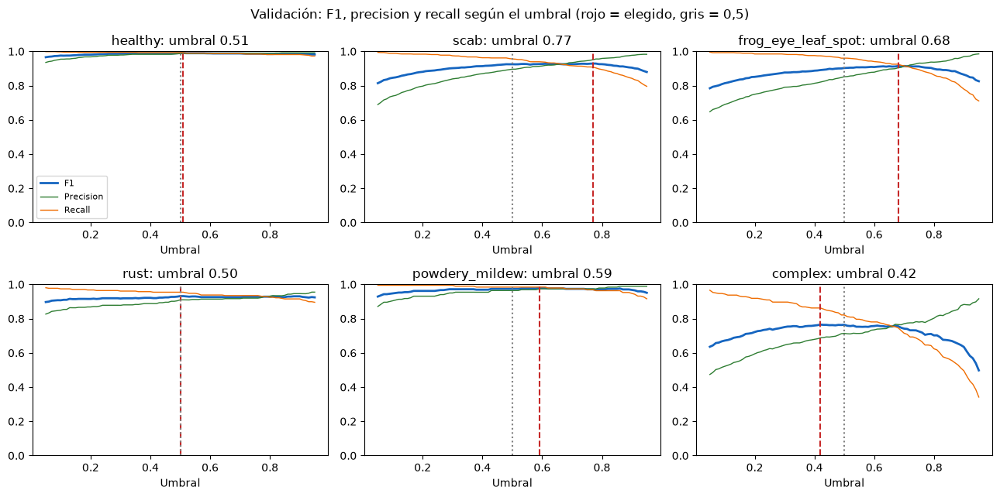

In [38]:
# Importa las métricas F1, precisión y recall para evaluar las predicciones del modelo
from sklearn.metrics import f1_score, precision_score, recall_score

# Carga el archivo CSV con las probabilidades predichas para cada etiqueta en el conjunto de validación
validacion = pd.read_csv(cfg.RESULTADOS / "probabilidades_validacion.csv")
# Carga el archivo CSV con las probabilidades predichas para cada etiqueta en el conjunto de prueba
prueba = pd.read_csv(cfg.RESULTADOS / "probabilidades_prueba.csv")
# Genera una lista de umbrales entre 0.05 y 0.95, con incrementos de 0.01 y redondeados a dos decimales
candidatos = np.round(np.arange(0.05, 0.96, 0.01), 2)

# Crea una cuadrícula de dos filas y tres columnas para representar las métricas de cada clase
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
# Recorre las clases junto con su índice para asignar cada gráfico a una posición de la cuadrícula
for indice, clase in enumerate(clases):
    # Selecciona el gráfico correspondiente a la posición de la clase en la cuadrícula
    eje = ejes[indice // 3, indice % 3]
    # Recorre las métricas F1, precisión y recall, junto con sus colores para diferenciarlas en la gráfica.}
    for nombre, func, color in (("F1", f1_score, "#1565c0"), ("Precision", precision_score, "#2e7d32"),
                                ("Recall", recall_score, "#ef6c00")):

        # Calcula la métrica correspondiente para cada umbral candidato
        # Compara las etiquetas reales con las predicciones binarias obtenidas al aplicar el umbral a las probabilidades
        # zero_division=0 devuelve 0 cuando la métrica no puede calcularse por una división entre cero
        valores = [func(validacion[clase], validacion[f"prob_{clase}"] >= u, zero_division=0) for u in candidatos]
        # Dibuja la evolución de la métrica según el umbral, utilizando un grosor mayor para la curva F1.
        eje.plot(candidatos, valores, color=color, label=nombre, lw=2 if nombre == "F1" else 1)

# Dibuja una línea vertical roja discontinua en el umbral elegido durante la validación para esta clase
    eje.axvline(umbrales[clase], color="#c62828", linestyle="--")
# Dibuja una línea vertical gris punteada para señalar el umbral convencional de 0.5
    eje.axvline(0.5, color="gray", linestyle=":")
# Añade el nombre de la clase y el umbral seleccionado al título del gráfico
    eje.set_title(f"{clase}: umbral {umbrales[clase]:.2f}")
# Establece los límites del eje vertical entre 0 y 1, rango habitual de estas métricas.
    eje.set_ylim(0, 1)
# Etiqueta el eje horizontal para indicar que representa los umbrales evaluados.
    eje.set_xlabel("Umbral")
# Muestra la leyenda en el primer gráfico para identificar las curvas de F1, precisión y recall.
ejes[0, 0].legend(fontsize=8)
plt.suptitle("Validación: F1, precision y recall según el umbral (rojo = elegido, gris = 0,5)")
# Ajusta los espacios entre los gráficos para mejorar su distribución dentro de la figura.
plt.tight_layout()
plt.show()

### 6.1 Resultado en la prueba

Las tablas siguientes usan los umbrales congelados
`complex` suele ser la etiqueta más débil: en el concurso marca hojas con varias enfermedades difíciles de separar, así que el propio dato es más ambiguo

In [39]:
# Crea una lista vacía donde se guardarán los resultados de las métricas para cada etiqueta y umbral
filas = []

# Recorre cada enfermedad de la hoja para evaluar sus predicciones
for clase in clases:
    # Obtiene las etiquetas reales de la clase actual y las convierte en un arreglo de NumPy
    reales = prueba[clase].to_numpy()
    # Obtiene las probabilidades predichas por el modelo para la clase actual y las convierte en un arreglo de NumPy
    probs = prueba[f"prob_{clase}"].to_numpy()

    # Compara dos umbrales: el valor fijo de 0.5 y el umbral seleccionado durante la validación para esta clase
    for nombre, corte in (("0.50", 0.5), ("validación", umbrales[clase])):
        # Convierte las probabilidades en predicciones binarias: 1 si alcanzan el umbral y 0 si quedan por debajo
        predichas = (probs >= corte).astype(int)
        # Guarda en una fila el nombre de la etiqueta, el umbral utilizado, su origen y las métricas calculadas
        filas.append({
            "Etiqueta": clase,           # Identifica la enfermedad o el estado evaluado
            "Umbral": corte,             # Registra el valor del umbral utilizado para generar las predicciones
            "Origen": nombre,           # Indica si se utilizó el umbral fijo de 0.5 o el elegido durante la validación
            "Precision": round(precision_score(reales, predichas, zero_division=0), 3),     # Calcula la precisión y redondea el resultado a tres decimales
            "Recall": round(recall_score(reales, predichas, zero_division=0), 3),          # Calcula el recall y redondea el resultado a tres decimales
            "F1": round(f1_score(reales, predichas, zero_division=0), 3),              # Calcula la puntuación F1 y redondea el resultado a tres decimales
        })

# Convierte la lista de resultados en un DataFrame para organizar las métricas en una tabla comparativa.
comparacion = pd.DataFrame(filas)
comparacion

,Etiqueta,Umbral,Origen,Precision,Recall,F1
0,healthy,0.50,0.50,0.973,0.994,0.984
1,healthy,0.51,validación,0.973,0.994,0.984
2,scab,0.50,0.50,0.896,0.939,0.917
3,scab,0.77,validación,0.953,0.894,0.922
4,frog_eye_leaf_spot,0.50,0.50,0.842,0.949,0.893
5,frog_eye_leaf_spot,0.68,validación,0.899,0.904,0.901
6,rust,0.50,0.50,0.915,0.954,0.934
7,rust,0.50,validación,0.915,0.954,0.934
8,powdery_mildew,0.50,0.50,0.978,0.932,0.954
9,powdery_mildew,0.59,validación,0.978,0.932,0.954


In [40]:
# Carga el archivo CSV con las métricas obtenidas durante la evaluación del conjunto de prueba
detalle = pd.read_csv(cfg.RESULTADOS / "metricas_prueba.csv")

# Calcula la exactitud de cada etiqueta dividiendo los aciertos totales (VN + VP) entre el total de casos evaluados
# VN son los verdaderos negativos y VP los verdaderos positivos; FP son los falsos positivos y FN los falsos negativos
detalle["Exactitud"] = ((detalle["VN"] + detalle["VP"]) / (detalle["VN"] + detalle["FP"] + detalle["FN"] + detalle["VP"])).round(3)
detalle.round(3)

,Etiqueta,Umbral,Precision,Recall,F1,ROC_AUC,PR_AUC,VN,FP,FN,VP,Exactitud
0,healthy,0.51,0.973,0.994,0.984,1.000,0.999,2074,19,4,689,0.992
1,scab,0.77,0.953,0.894,0.922,0.990,0.982,1891,38,91,766,0.954
2,frog_eye_leaf_spot,0.68,0.899,0.904,0.901,0.989,0.969,2067,66,63,590,0.954
3,rust,0.50,0.915,0.954,0.934,0.998,0.988,2454,27,14,291,0.985
4,powdery_mildew,0.59,0.978,0.932,0.954,0.999,0.992,2591,4,13,178,0.994
5,complex,0.42,0.698,0.884,0.780,0.980,0.868,2345,122,37,282,0.943


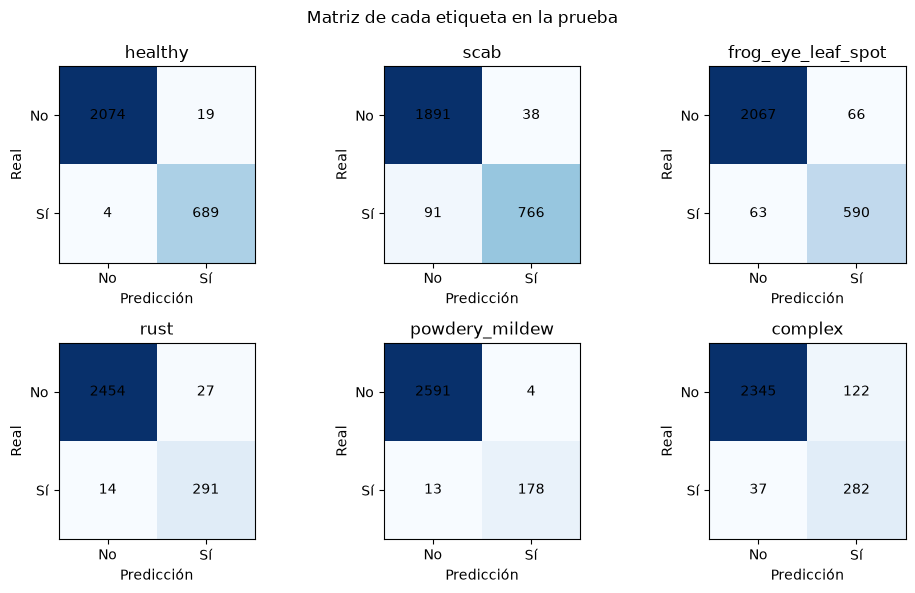

F1 macro con umbral 0.50: 0.912
F1 macro con umbrales de validación: 0.913
F1 micro (umbrales calibrados): 0.918
F1 por muestra (métrica del concurso): 0.935
Fotos con TODAS sus etiquetas correctas: 87.4 %


In [41]:
# Crea una figura con dos filas y tres columnas para mostrar las matrices de confusión de las distintas etiquetas
fig, ejes = plt.subplots(2, 3, figsize=(10, 6))

# Recorre cada clase junto con su índice para construir su matriz de confusión
for indice, clase in enumerate(clases):
# Busca en la tabla de métricas la fila correspondiente a la clase actual y obtiene sus datos
    fila = detalle.loc[detalle["Etiqueta"] == clase].iloc[0]
# Construye la matriz de confusión de 2 × 2 con los verdaderos negativos, falsos positivos,
# falsos negativos y verdaderos positivos, organizados según sus posiciones habituales
    matriz = np.array([[fila["VN"], fila["FP"]], [fila["FN"], fila["VP"]]], dtype=float)
 # Selecciona el gráfico correspondiente a la clase actual dentro de la cuadrícula
    eje = ejes[indice // 3, indice % 3]
# Representa la matriz de confusión mediante un mapa de colores azules
    eje.imshow(matriz, cmap="Blues")
# Define las etiquetas del eje horizontal para distinguir las predicciones negativas y positivas
    eje.set_xticks([0, 1], ["No", "Sí"])
# Define las etiquetas del eje vertical para distinguir los valores reales negativos y positivos
    eje.set_yticks([0, 1], ["No", "Sí"])
 # Etiqueta el eje horizontal para indicar que representa las predicciones del modelo
    eje.set_xlabel("Predicción")
# Etiqueta el eje vertical para indicar que representa las etiquetas reales
    eje.set_ylabel("Real")
    eje.set_title(clase)

 # Recorre las dos filas de la matriz para escribir los valores dentro de cada celda
    for fila_matriz in range(2):
# Recorre las dos columnas de la matriz para identificar cada celda
        for columna in range(2):
# Muestra el valor entero de cada celda centrado horizontal y verticalmente
            eje.text(columna, fila_matriz, int(matriz[fila_matriz, columna]), ha="center", va="center")

plt.suptitle("Matriz de cada etiqueta en la prueba")
# Ajusta los espacios entre los gráficos para mejorar su distribución
plt.tight_layout()
plt.show()

# Calcula el promedio de las puntuaciones F1 de las etiquetas evaluadas con el umbral fijo de 0.50 y muestra el resultado
print("F1 macro con umbral 0.50:", round(comparacion.loc[comparacion["Origen"] == "0.50", "F1"].mean(), 3))
# Calcula el promedio de las puntuaciones F1 de las etiquetas evaluadas con los umbrales seleccionados durante la validación
print("F1 macro con umbrales de validación:", round(comparacion.loc[comparacion["Origen"] == "validación", "F1"].mean(), 3))
# Muestra la puntuación F1 micro obtenida en el conjunto de prueba con los umbrales calibrados
# Esta métrica acumula los verdaderos positivos, falsos positivos y falsos negativos de todas las etiquetas
print("F1 micro (umbrales calibrados):", round(resumen_prueba["f1_micro_prueba"], 3))
# Muestra la puntuación F1 por muestra, que evalúa las predicciones considerando las etiquetas de cada imagen
print("F1 por muestra (métrica del concurso):", round(resumen_prueba["f1_muestras_prueba"], 3))

# Muestra el porcentaje de fotografías en las que todas las etiquetas fueron predichas correctamente
print("Fotos con TODAS sus etiquetas correctas:", f"{100 * resumen_prueba['exactitud_exacta_prueba']:.1f} %")

### 6.2 Curvas ROC y precisión-recall

La curva **ROC** compara aciertos y falsas alarmas para todos los umbrales posibles; su área (ROC-AUC) es la probabilidad de que una hoja enferma reciba más puntuación que una sana. La curva **precisión-recall** es más exigente cuando la clase es escasa (oídio, roya): una clase rara puede tener ROC-AUC alto y aun así muchas falsas alarmas.

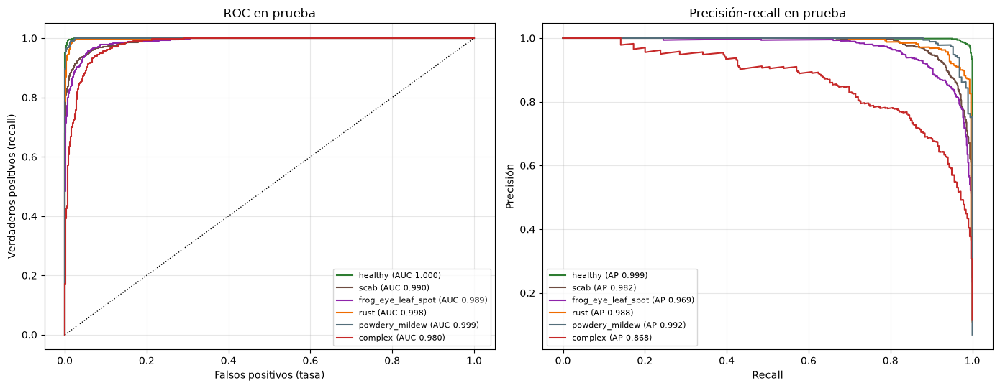

In [42]:
# Importa las métricas para calcular las curvas ROC, precisión-recall y sus áreas correspondientes
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

# Crea una figura con dos gráficos organizados en una fila para comparar el rendimiento del modelo
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
# Recorre cada enfermedad o estado de la hoja para evaluar las predicciones del modelo
for clase in clases:
# Obtiene las etiquetas reales de la clase actual y las probabilidades predichas por el modelo
    y, p = prueba[clase], prueba[f"prob_{clase}"]
# Calcula la tasa de falsos positivos (fpr) y la tasa de verdaderos positivos (tpr) para construir la curva ROC
    fpr, tpr, _ = roc_curve(y, p)
# Calcula los valores de precisión y recall para construir la curva precisión-recall
    pre, rec, _ = precision_recall_curve(y, p)
# Obtiene el color asignado a la clase actual desde la configuración del proyecto
    color = cfg.COLORES[clase]

# Dibuja la curva ROC de la clase actual y muestra su área bajo la curva (AUC) en la leyenda
# un AUC mayor indica, en general, una mejor capacidad para distinguir entre casos positivos y negativos
    ejes[0].plot(fpr, tpr, color=color, label=f"{clase} (AUC {roc_auc_score(y, p):.3f})")

# Dibuja la curva precisión-recall de la clase actual y muestra su Average Precision (AP) en la leyenda
# esta métrica resume el rendimiento de la precisión a distintos niveles de recall
    ejes[1].plot(rec, pre, color=color, label=f"{clase} (AP {average_precision_score(y, p):.3f})")

# Dibuja una línea diagonal de referencia en la gráfica ROC para representar el comportamiento de un clasificador aleatorio
ejes[0].plot([0, 1], [0, 1], "k:", lw=1)
ejes[0].set(title="ROC en prueba", xlabel="Falsos positivos (tasa)", ylabel="Verdaderos positivos (recall)")
ejes[1].set(title="Precisión-recall en prueba", xlabel="Recall", ylabel="Precisión")

# Recorre ambos gráficos para añadir elementos que faciliten la interpretación
for ax in ejes:
    # Muestra la leyenda con las clases y sus métricas AUC o AP correspondientes
    ax.legend(fontsize=8)
    # Añade una cuadrícula con transparencia para facilitar la lectura de los valores
    ax.grid(alpha=0.3)

# Ajusta los espacios de la figura para que los gráficos y sus leyendas se distribuyan correctamente
plt.tight_layout()
plt.show()

### 6.3 Matriz de confusión multietiqueta

En multietiqueta no existe una única matriz de confusión. Esta tabla responde: *de las hojas que realmente tienen la etiqueta de la fila, ¿qué porcentaje recibió cada etiqueta de la columna?* La diagonal es el recall; fuera de la diagonal se ve con qué se confunde cada enfermedad (por ejemplo, `complex` con `scab` o `frog_eye_leaf_spot`).

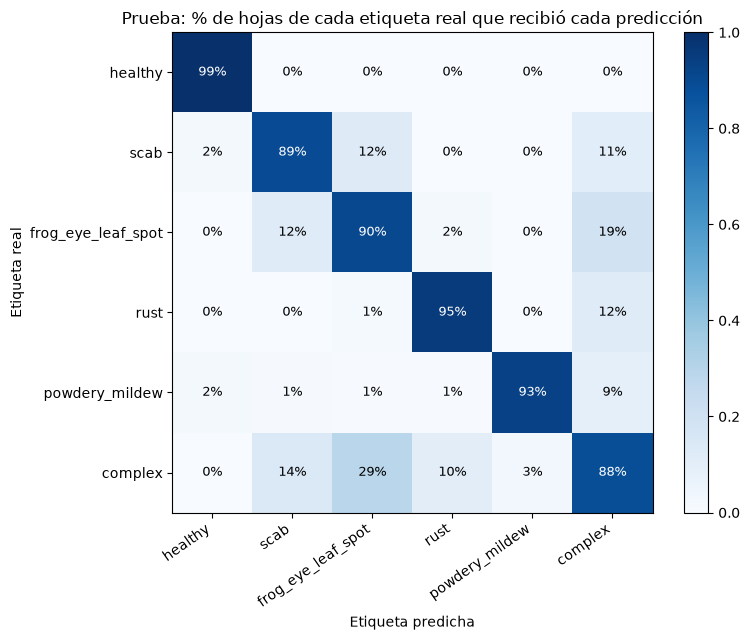

In [43]:
# Obtiene las etiquetas reales de todas las clases del conjunto de prueba y las convierte en un arreglo de NumPy
reales = prueba[clases].to_numpy()

# Genera las predicciones binarias para cada clase comparando sus probabilidades con los umbrales seleccionados durante la validación
# np.column_stack() combina las predicciones de todas las clases en una matriz y astype(int) convierte los valores booleanos en 0 y 1
predichas = np.column_stack([prueba[f"prob_{c}"] >= umbrales[c] for c in clases]).astype(int)

# Calcula una matriz que indica la proporción de imágenes de cada etiqueta real que también recibieron cada etiqueta predicha
# Cada fila representa una etiqueta real y cada columna una etiqueta predicha
matriz = np.array([[predichas[reales[:, i] == 1, j].mean() for j in range(len(clases))] for i in range(len(clases))])
# Crea una figura para visualizar la matriz de porcentajes
fig, ax = plt.subplots(figsize=(8, 6.5))
# Representa la matriz con una escala de colores azules cuyos valores van de 0 a 1
im = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
# Define las etiquetas del eje horizontal con los nombres de las clases predichas
ax.set_xticks(range(len(clases)), clases, rotation=35, ha="right")
# Define las etiquetas del eje vertical con los nombres de las clases reales
ax.set_yticks(range(len(clases)), clases)
ax.set_xlabel("Etiqueta predicha")
ax.set_ylabel("Etiqueta real")

# Recorre las filas de la matriz para añadir los porcentajes correspondientes a cada etiqueta real
for i in range(len(clases)):
    # Recorre las columnas de la matriz para añadir los porcentajes de cada etiqueta predicha
    for j in range(len(clases)):
        # Escribe el porcentaje de cada celda, redondeado al entero más cercano
        # Utiliza texto blanco cuando el valor supera 0.5 y negro en los demás casos para mejorar el contraste
        ax.text(j, i, f"{100 * matriz[i, j]:.0f}%", ha="center", va="center",
                color="white" if matriz[i, j] > 0.5 else "black", fontsize=9)

# Añade una barra de colores para interpretar la correspondencia entre los colores y los valores de la matriz.
plt.colorbar(im, fraction=0.046)
plt.title("Prueba: % de hojas de cada etiqueta real que recibió cada predicción")
plt.tight_layout()
plt.show()

### 6.4 Errores en fotos reales

Cada par muestra, para una etiqueta, un falso positivo con probabilidad alta y un falso negativo con probabilidad baja. Son ejemplos del conjunto de prueba, no una muestra para volver a ajustar el modelo.

Varios falsos positivos están etiquetados como `complex` o como otra enfermedad. La explicación de la sección 7 tendrá que revisarse con esa reserva: una probabilidad alta no demuestra dónde está la lesión.

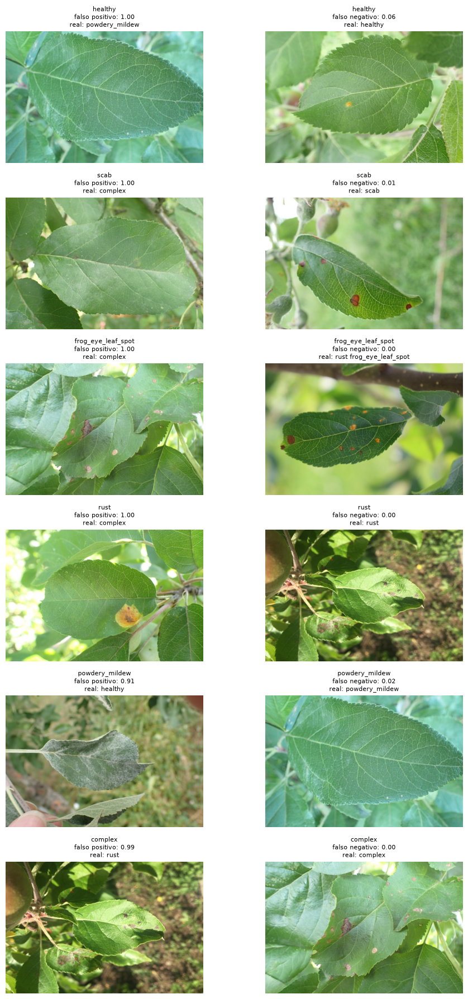

In [44]:
# Carga el archivo CSV que contiene los errores identificados durante la evaluación del conjunto de prueba
errores = pd.read_csv(cfg.RESULTADOS / "errores_prueba.csv")

# Crea una figura para mostrar las imágenes con errores
plt.figure(figsize=(10, 3 * ((len(errores) + 1) // 2)))

# Recorre cada registro del archivo de errores junto con su índice para visualizar las imágenes
for indice, fila in enumerate(errores.itertuples(index=False)):
# Abre la imagen correspondiente desde la carpeta de caché y la convierte al formato RGB
    imagen = Image.open(cfg.CACHE / fila.image).convert("RGB")
# Crea un espacio dentro de la cuadrícula para mostrar la imagen actual
# organiza las imágenes en dos columnas y tantas filas como sean necesarias
    plt.subplot((len(errores) + 1) // 2, 2, indice + 1)
 # Muestra la imagen correspondiente al error identificado
    plt.imshow(imagen)

# Añade un título con la etiqueta evaluada, el tipo de error, la probabilidad predicha y las etiquetas reales
# fontsize=8 reduce el tamaño del texto para facilitar su visualización
    plt.title(f"{fila.Etiqueta}\n{fila.Tipo}: {fila.Probabilidad:.2f}\nreal: {fila.labels}", fontsize=8)
# Oculta los ejes para centrar la atención en las imágenes y sus resultados.
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Explicación visual: ¿por qué el modelo dice que está enferma?

### 7.1 Qué herramienta conviene

| Opción | Qué necesita para entrenarse | ¿Lo tiene este dataset? | Decisión |
|---|---|---|---|
| **YOLO (detección)** | Una caja dibujada a mano alrededor de **cada mancha** en miles de fotos | No: solo hay una etiqueta por foto | Descartado. Entrenarlo exigiría inventar cajas o etiquetar a mano miles de lesiones |
| **Segmentación de lesiones (U-Net, YOLO-seg)** | Máscara píxel a píxel de cada lesión | No | Descartado por la misma razón |
| **Clasificador + mapa de atención (Grad-CAM / LayerCAM)** | Solo etiquetas por foto | Sí | **Usado**: muestra dónde mira el modelo |
| **Visión clásica (color Lab, enfoque, GrabCut)** | Nada: reglas explicables | Sí | **Usado**: da el contorno exacto de cada mancha |
| **Prueba de borrado (oclusión)** | El propio modelo | Sí | **Usado**: comprueba que la decisión depende de esas manchas |

YOLO es excelente cuando existen cajas anotadas (por ejemplo, para contar frutos). Aquí no existen, y el propio planteamiento del proyecto prohíbe inventar anotaciones. La combinación elegida localiza las manchas sin datos falsos y además **verifica** la explicación.

### 7.2 Cómo funciona el análisis de una foto

1. **Probabilidades:** el clasificador da una probabilidad por etiqueta; los umbrales de validación deciden qué se marca.
2. **Mapa de atención (LayerCAM en dos capas):** la capa profunda de la red (1/32 de resolución) indica *qué zona* empuja la probabilidad de cada enfermedad; una capa intermedia (1/16) afina *dónde*, con el doble de detalle que el Grad-CAM anterior de 7×7.
3. **Hoja y manchas por color:** se separa la hoja del fondo (enfoque + GrabCut) y se buscan píxeles cuyo color se aleja del verde sano **de esa misma hoja** hacia el marrón, rojo, amarillo o blanco.
4. **Evidencias:** una mancha es evidencia de una enfermedad si cae donde el modelo concentra su atención para esa enfermedad (atención media ≥ 0,35). Se dibuja con un **círculo numerado** del color de la enfermedad. Si el modelo mira una zona sin mancha de color definida (síntoma difuso), se dibuja un círculo **discontinuo**.
5. **Prueba de borrado:** las evidencias se borran digitalmente y se vuelve a preguntar al modelo. Si la probabilidad cae mucho más que al borrar la misma área de tejido sano al azar, la decisión depende de esas manchas.
6. **Coherencia con el síntoma:** se compara el color de las evidencias con la descripción típica de la enfermedad (roya: anaranjado; oídio: blanquecino; ojo de rana: marrón con centro claro…).

**Qué no significa:** los círculos explican la predicción del modelo.. no son una delimitación de laboratorio. Una zona resaltada no está enferma "con certeza" por aparecer en el mapa.


Etiqueta REAL: rust


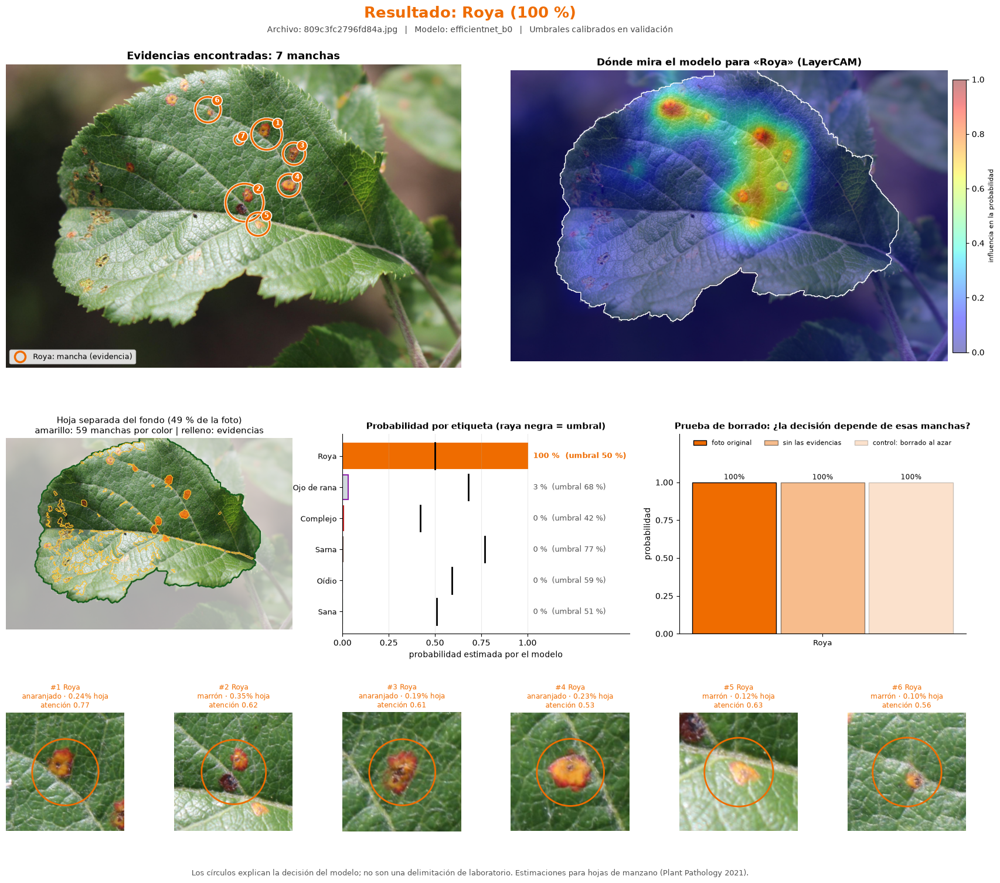

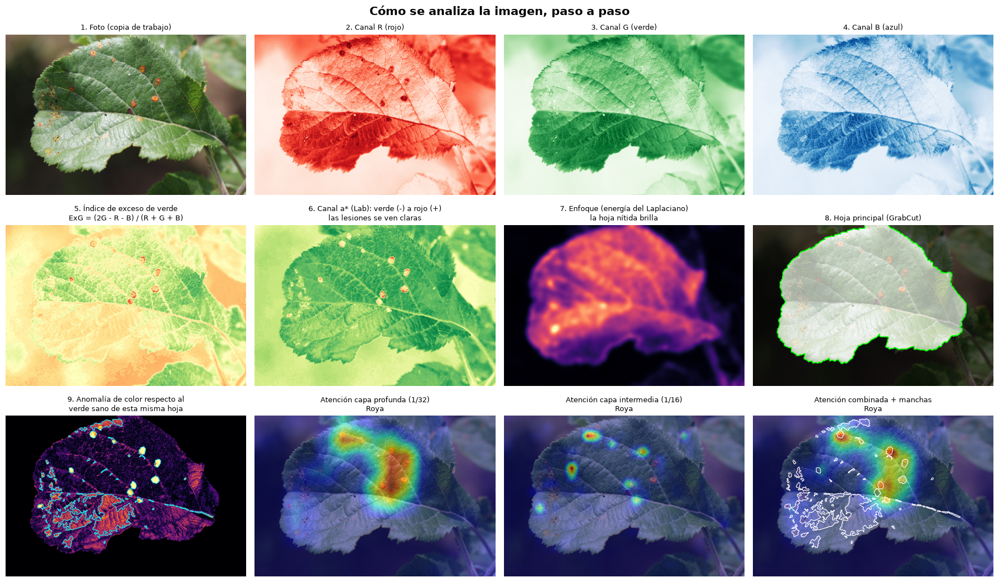

### Resultado del análisis — `809c3fc2796fd84a.jpg`
- Etiquetas que superan su umbral: **Roya** (100 %, umbral 50 %).
- Etiqueta más probable: **Roya** (100 %). Es una estimación del modelo, no un diagnóstico definitivo.

### Por qué el modelo llega a esta conclusión
**Roya.** Se encontraron **7 manchas** dentro de la hoja que coinciden con las zonas donde el modelo concentra su atención (círculos #1, #2, #3, #4, #5, #6, #7). Ocupan cerca del **1.2 % de la hoja** y reúnen el **10 % de la atención** del modelo para esta etiqueta, unas 8 veces más de lo que les tocaría por su tamaño.
  - Color de esas manchas: anaranjado (53 %), marrón (46 %), blanquecino (1 %).
  - Síntoma típico de roya: manchas amarillo-anaranjadas brillantes, a menudo con borde rojizo y puntos oscuros en el centro (Gymnosporangium juniperi-virginianae). El color observado **coincide** con esa descripción (99 % del área).
  - **Prueba de borrado:** al borrar digitalmente esas zonas, la probabilidad pasa de 100 % a **100 %**; borrando la misma área en tejido sano al azar queda en 100 %. La probabilidad casi no cambia: el modelo se apoya en rasgos más repartidos (textura, tono general) y no solo en esas manchas.
  - Extensión visible aproximada: **baja** (1.2 % de la hoja). Orientativo; no es una escala fitopatológica validada.

### Calidad de la foto y fiabilidad
- La foto está dentro de los rangos de brillo, contraste y nitidez del entrenamiento.
- Hoja segmentada con GrabCut guiado por enfoque: ocupa el 49 % de la foto.

*Cómo leer los círculos:* línea continua = mancha de color que el modelo usa como evidencia; línea discontinua = zona donde el modelo mira sin una mancha definida. Los círculos explican la predicción del modelo; no son una delimitación de laboratorio de la lesión. El modelo se entrenó con hojas de manzano de Plant Pathology 2021 y no se ha validado con otras especies, cámaras o condiciones de campo.

In [45]:
# Importa el módulo de interfaz del proyecto para disponer de sus funciones relacionadas con la interacción del sistema
from codigo import interfaz
# Importa la función para analizar imágenes y la función para cargar el sistema de diagnóstico
from codigo.diagnostico import analizar, cargar_sistema

cargar_sistema()
# Obtiene la división correspondiente al conjunto de prueba
prueba_div = leer_division("prueba")
# Selecciona la primera imagen del conjunto de prueba cuya etiqueta real sea "rust"
ejemplo = prueba_div[prueba_div["labels"] == "rust"].iloc[0]
# Muestra la etiqueta real de la imagen seleccionada para conocer su clasificación original
print("Etiqueta REAL:", ejemplo["labels"])
# Analiza la imagen seleccionada utilizando su ruta dentro de la carpeta de imágenes
resultado = analizar(carpeta_imagenes / ejemplo["image"], pasos=True, guardar=False)


Etiqueta REAL de e0f197cac8a5b532.jpg: frog_eye_leaf_spot


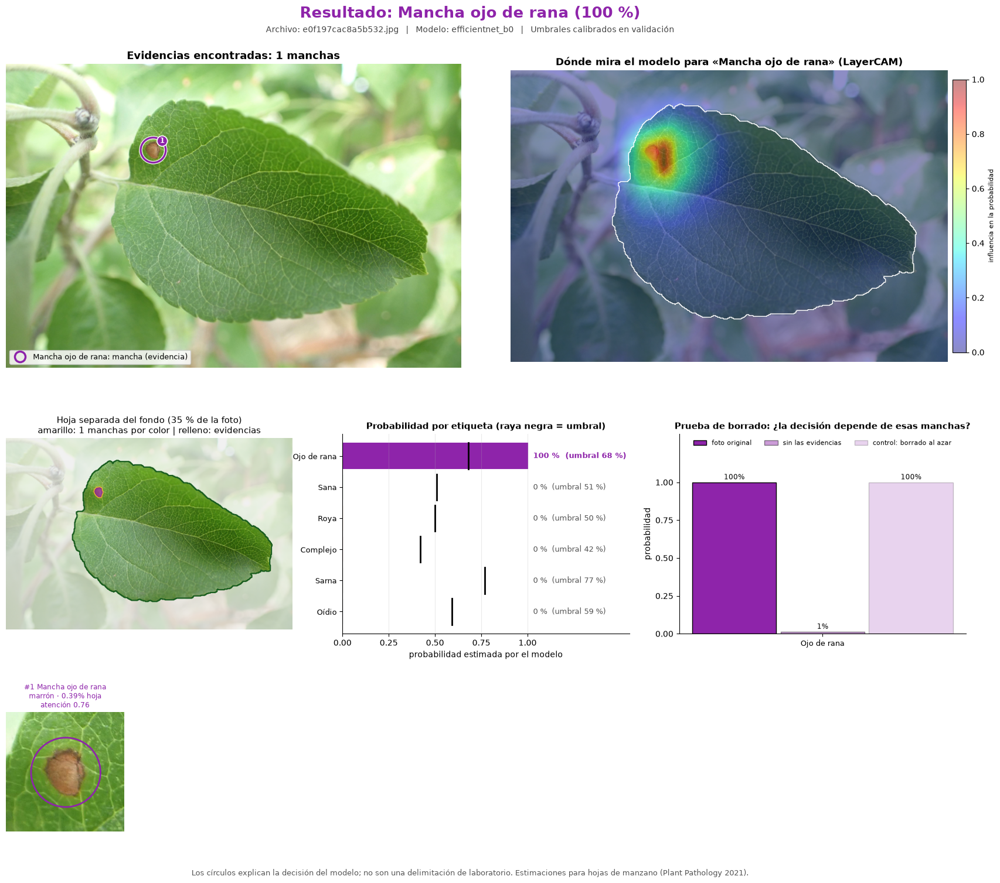

### Resultado del análisis — `e0f197cac8a5b532.jpg`
- Etiquetas que superan su umbral: **Mancha ojo de rana** (100 %, umbral 68 %).
- Etiqueta más probable: **Mancha ojo de rana** (100 %). Es una estimación del modelo, no un diagnóstico definitivo.

### Por qué el modelo llega a esta conclusión
**Mancha ojo de rana.** Se encontró **1 mancha** dentro de la hoja que coincide con las zonas donde el modelo concentra su atención (círculos #1). Ocupa cerca del **0.4 % de la hoja** y reúne el **6 % de la atención** del modelo para esta etiqueta, unas 14 veces más de lo que le tocaría por su tamaño.
  - Color de esas manchas: marrón (100 %).
  - Síntoma típico de mancha ojo de rana: manchas redondeadas marrones con el centro más claro y un borde más oscuro o púrpura, como un ojo (Botryosphaeria obtusa). El color observado **coincide** con esa descripción (100 % del área).
  - 1 mancha muestra el centro más claro que el borde, el patrón de "ojo" característico.
  - **Prueba de borrado:** al borrar digitalmente esas zonas, la probabilidad pasa de 100 % a **1 %**; borrando la misma área en tejido sano al azar queda en 100 %. **La decisión depende de esas manchas.**
  - Extensión visible aproximada: **baja** (0.4 % de la hoja). Orientativo; no es una escala fitopatológica validada.

### Calidad de la foto y fiabilidad
- La foto está dentro de los rangos de brillo, contraste y nitidez del entrenamiento.
- Hoja segmentada con GrabCut guiado por enfoque: ocupa el 35 % de la foto.

*Cómo leer los círculos:* línea continua = mancha de color que el modelo usa como evidencia; línea discontinua = zona donde el modelo mira sin una mancha definida. Los círculos explican la predicción del modelo; no son una delimitación de laboratorio de la lesión. El modelo se entrenó con hojas de manzano de Plant Pathology 2021 y no se ha validado con otras especies, cámaras o condiciones de campo.


Etiqueta REAL de ff9ce05083e01fe2.jpg: scab


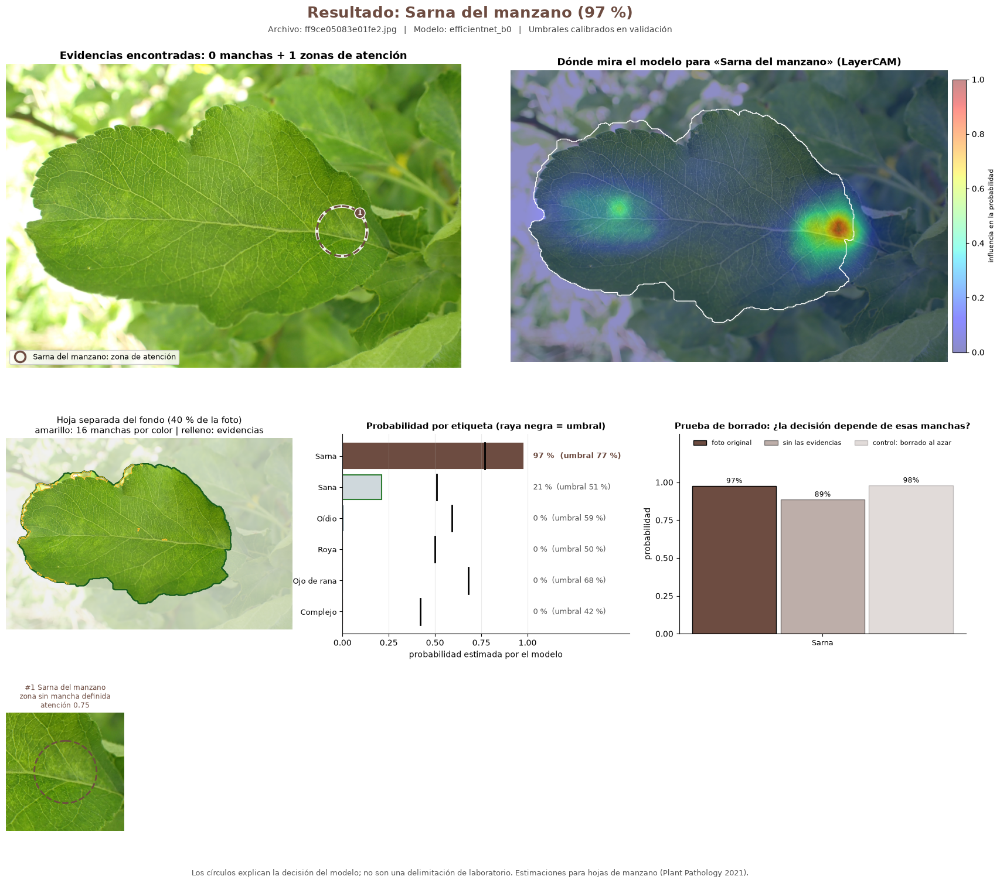

### Resultado del análisis — `ff9ce05083e01fe2.jpg`
- Etiquetas que superan su umbral: **Sarna del manzano** (97 %, umbral 77 %).
- Etiqueta más probable: **Sarna del manzano** (97 %). Es una estimación del modelo, no un diagnóstico definitivo.

### Por qué el modelo llega a esta conclusión
**Sarna del manzano.** No aparece una mancha de color bien delimitada, pero el modelo se fija en 1 zona(s) de la hoja (círculos discontinuos #1). Puede tratarse de un síntoma difuso, de textura (p. ej. sarna incipiente u oídio tenue) o de algo que el modelo asocia a esa etiqueta sin ser una lesión: conviene mirar esas zonas de cerca.
  - **Prueba de borrado:** al borrar digitalmente esas zonas, la probabilidad pasa de 97 % a **89 %**; borrando la misma área en tejido sano al azar queda en 98 %. Esas manchas influyen, pero el modelo también usa otras partes de la foto.

### Calidad de la foto y fiabilidad
- La foto está dentro de los rangos de brillo, contraste y nitidez del entrenamiento.
- Hoja segmentada con GrabCut guiado por enfoque: ocupa el 40 % de la foto.

*Cómo leer los círculos:* línea continua = mancha de color que el modelo usa como evidencia; línea discontinua = zona donde el modelo mira sin una mancha definida. Los círculos explican la predicción del modelo; no son una delimitación de laboratorio de la lesión. El modelo se entrenó con hojas de manzano de Plant Pathology 2021 y no se ha validado con otras especies, cámaras o condiciones de campo.


Etiqueta REAL de e160ddea201fe29d.jpg: powdery_mildew


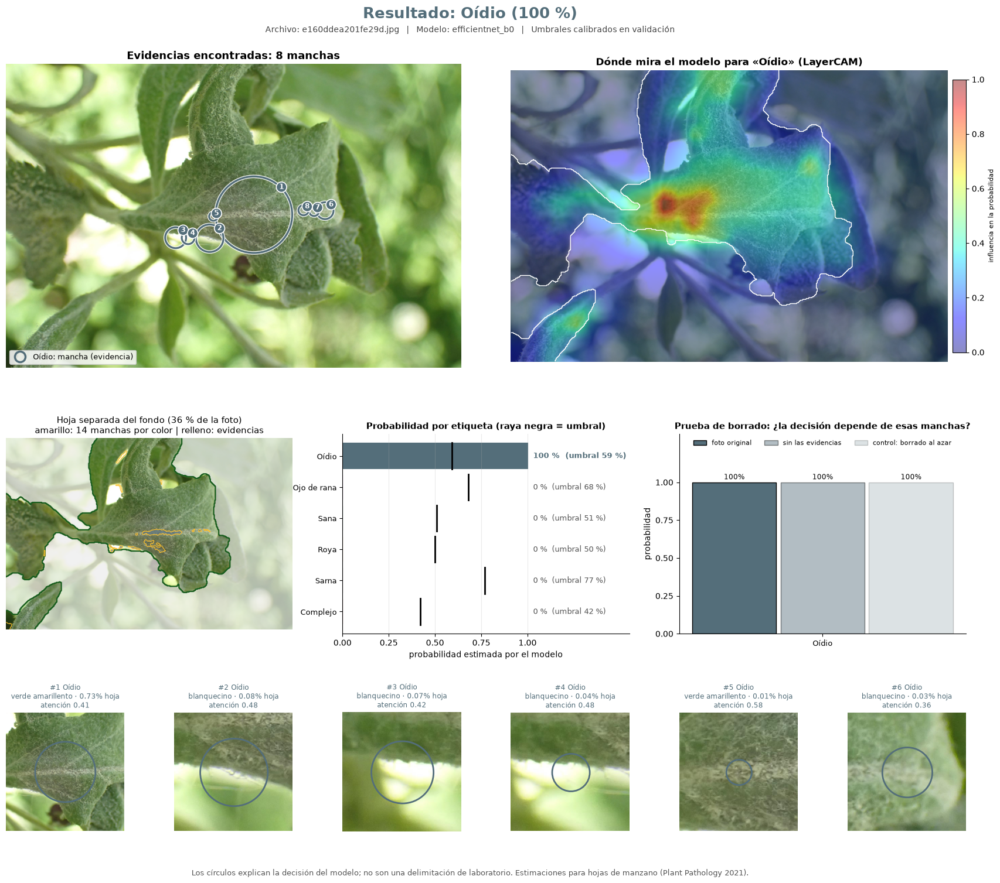

### Resultado del análisis — `e160ddea201fe29d.jpg`
- Etiquetas que superan su umbral: **Oídio** (100 %, umbral 59 %).
- Etiqueta más probable: **Oídio** (100 %). Es una estimación del modelo, no un diagnóstico definitivo.

### Por qué el modelo llega a esta conclusión
**Oídio.** Se encontraron **8 manchas** dentro de la hoja que coinciden con las zonas donde el modelo concentra su atención (círculos #1, #2, #3, #4, #5, #6, #7, #8). Ocupan cerca del **1.0 % de la hoja** y reúnen el **3 % de la atención** del modelo para esta etiqueta, unas 3 veces más de lo que les tocaría por su tamaño.
  - Color de esas manchas: verde amarillento (74 %), blanquecino (26 %).
  - Síntoma típico de oídio: capa blanquecina o grisácea de aspecto polvoriento sobre la hoja, que puede verse arrugada o deformada (Podosphaera leucotricha). El color observado **no coincide bien** con esa descripción (26 % del área).
  - **Prueba de borrado:** al borrar digitalmente esas zonas, la probabilidad pasa de 100 % a **100 %**; borrando la misma área en tejido sano al azar queda en 100 %. La probabilidad casi no cambia: el modelo se apoya en rasgos más repartidos (textura, tono general) y no solo en esas manchas.
  - Extensión visible aproximada: **baja** (1.0 % de la hoja). Orientativo; no es una escala fitopatológica validada.

### Calidad de la foto y fiabilidad
- La foto está dentro de los rangos de brillo, contraste y nitidez del entrenamiento.
- Hoja segmentada con GrabCut guiado por enfoque: ocupa el 36 % de la foto.

*Cómo leer los círculos:* línea continua = mancha de color que el modelo usa como evidencia; línea discontinua = zona donde el modelo mira sin una mancha definida. Los círculos explican la predicción del modelo; no son una delimitación de laboratorio de la lesión. El modelo se entrenó con hojas de manzano de Plant Pathology 2021 y no se ha validado con otras especies, cámaras o condiciones de campo.


Etiqueta REAL de b4e7cf1af036042d.jpg: scab frog_eye_leaf_spot complex


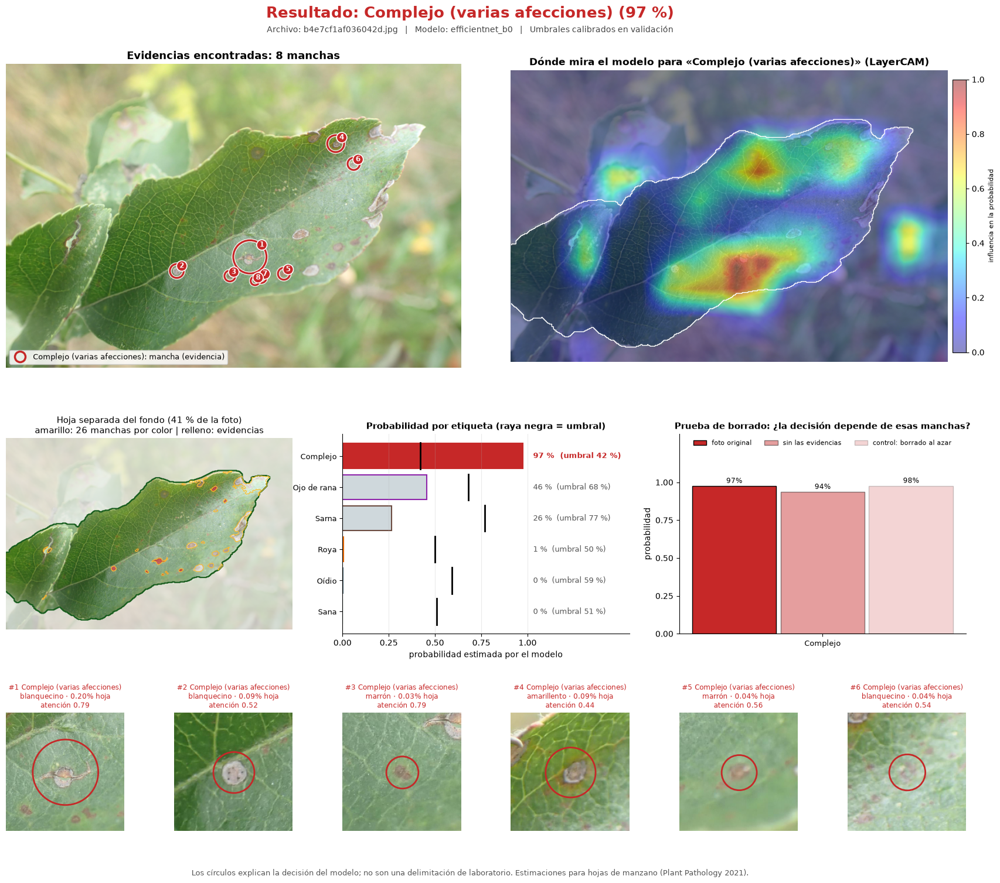

### Resultado del análisis — `b4e7cf1af036042d.jpg`
- Etiquetas que superan su umbral: **Complejo (varias afecciones)** (97 %, umbral 42 %).
- Etiqueta más probable: **Complejo (varias afecciones)** (97 %). Es una estimación del modelo, no un diagnóstico definitivo.

### Por qué el modelo llega a esta conclusión
**Complejo (varias afecciones).** Se encontraron **8 manchas** dentro de la hoja que coinciden con las zonas donde el modelo concentra su atención (círculos #1, #2, #3, #4, #5, #6, #7, #8). Ocupan cerca del **0.5 % de la hoja** y reúnen el **3 % de la atención** del modelo para esta etiqueta, unas 7 veces más de lo que les tocaría por su tamaño.
  - Color de esas manchas: blanquecino (63 %), amarillento (20 %), marrón (17 %).
  - Complejo (varias afecciones): varias afecciones en la misma hoja o síntomas que no encajan claramente en una sola categoría (así define el concurso esta etiqueta).
  - **Prueba de borrado:** al borrar digitalmente esas zonas, la probabilidad pasa de 97 % a **94 %**; borrando la misma área en tejido sano al azar queda en 98 %. La probabilidad casi no cambia: el modelo se apoya en rasgos más repartidos (textura, tono general) y no solo en esas manchas.
  - Extensión visible aproximada: **baja** (0.5 % de la hoja). Orientativo; no es una escala fitopatológica validada.

### Calidad de la foto y fiabilidad
- La foto está dentro de los rangos de brillo, contraste y nitidez del entrenamiento.
- Hoja segmentada con GrabCut guiado por enfoque: ocupa el 41 % de la foto.

*Cómo leer los círculos:* línea continua = mancha de color que el modelo usa como evidencia; línea discontinua = zona donde el modelo mira sin una mancha definida. Los círculos explican la predicción del modelo; no son una delimitación de laboratorio de la lesión. El modelo se entrenó con hojas de manzano de Plant Pathology 2021 y no se ha validado con otras especies, cámaras o condiciones de campo.

In [47]:
# Muestra una galería con 4 imágenes del conjunto de prueba para visualizar ejemplos y sus resultados
interfaz.galeria_prueba(n=4)

## 8. Analizar una foto propia

elegimos la hoja a analizar

In [48]:
# mostramos el panel principal de la interfaz para interactuar con el sistema de diagnóstico
interfaz.panel()

**Alternativa sin widgets.** 

In [ ]:
# resultados = interfaz.elegir_y_analizar(pasos=True)

## 9. Conclusiones, decisiones técnicas y limitaciones

### Resumen de decisiones

| Decisión | Motivo |
|---|---|
| Multietiqueta con 6 sigmoides y BCE | Una hoja puede tener varias enfermedades; softmax obligaría a elegir una |
| División por grupos de duplicados, estratificada | Evita fugas y conserva la proporción de cada etiqueta |
| EfficientNet con transfer learning, 576×384 / 480×320 | Más resolución para lesiones pequeñas; misma familia para CPU y GPU |
| Peso de positivos √(neg/pos) | Atiende el desbalance sin inflar las probabilidades |
| Checkpoint por pérdida de validación; umbrales por F1 en validación | Criterios fijados antes de ver la prueba |
| TTA (espejo horizontal) | Predicción más estable sin coste de entrenamiento |
| LayerCAM + manchas por color + prueba de borrado | Localiza y verifica la explicación sin anotaciones inventadas |
| Código en `codigo/`, `analizar()` devuelve JSON | Reutilizable en una API web y una app Android |


### Referencias

- Thapa, R. et al. (2021). *Plant Pathology 2021 – FGVC8*. Kaggle. https://www.kaggle.com/competitions/plant-pathology-2021-fgvc8
- Tan, M. y Le, Q. (2019, 2021). *EfficientNet* y *EfficientNetV2*. ICML.
- Selvaraju, R. et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks*. ICCV.
- Jiang, P.-T. et al. (2021). *LayerCAM: Exploring Hierarchical Class Activation Maps for Localization*. IEEE TIP.
- Rother, C. et al. (2004). *GrabCut: Interactive Foreground Extraction using Iterated Graph Cuts*. SIGGRAPH.
- Telea, A. (2004). *An Image Inpainting Technique Based on the Fast Marching Method*. J. Graphics Tools.
- Zeiler, M. y Fergus, R. (2014). *Visualizing and Understanding Convolutional Networks* (oclusión). ECCV.
- Documentación de PyTorch y torchvision: https://pytorch.org/docs